| Step | What we’ll do | Why it matters |
|---|---|---|
| **1. Fix the experiment** | Choose one GPT-2 MLP layer, dataset, feature widths, sparsity settings, and training budget. Align with your teammate’s setup where practical. | Makes the experiment reproducible and comparable. |
| **2. Cache MLP inputs and outputs** | Collect pairs \(x \rightarrow \mathrm{MLP}(x)\), with separate training, validation, and test documents. | Prevents data leakage and avoids repeatedly running GPT-2 during training. |
| **3. Validate the evaluator** | Check identity interventions, direct MLP evaluation, tensor shapes, and response calculations. | Ensures apparent differences aren’t evaluation bugs. |
| **4. Train the three variants** | Learned, frozen encoder, and frozen decoder, with consistent initialization and data order. Record exactly which biases train and how decoder norms are handled. | Defines what our comparison actually tests. |
| **5. Check optimization** | For learned and frozen-encoder models, freeze their feature maps and refit unrestricted decoders using training data. Keep these as separate diagnostic branches. | Carries forward the lesson from our toy experiment. |
| **6. Build reconstruction–sparsity curves** | Measure validation reconstruction error and actual L0 across sparsity settings. Identify comparable models using validation data only. | Avoids attributing better reconstruction or more active features to better directions. |
| **7. Evaluate intervention responses** | Apply identical input edits to the original MLP and each transcoder. Compare their output changes on a fixed panel. | Tests the behavior we care about. |
| **8. Confirm and decide** | Repeat promising comparisons across seeds, lock model selection, then evaluate on held-out test data with uncertainty estimates. | Determines whether the result is reliable enough to continue. |

In [3]:
from pathlib import Path
import subprocess
import sys
import torch
repo_path = Path("/content/transcoder_circuits")

if not repo_path.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/jacobdunefsky/transcoder_circuits.git",
            str(repo_path),
        ],
        check=True,
    )

commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=repo_path,
    text=True,
).strip()

print("Repository:", repo_path)
print("Commit:", commit)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

print("\nRepository requirements:")
print((repo_path / "requirements.txt").read_text())

Repository: /content/transcoder_circuits
Commit: 8721ff06b64889e8cc50bb1c5e869c7f72b8303d
Python: 3.13.16
PyTorch: 2.14.1+cu130
GPU available: True

Repository requirements:
matplotlib
numpy
plotly
torch==2.2.0
tqdm
transformer_lens==1.11.0
datasets==2.12.0
einops==0.7.0
setuptools==67.7.2
wandb==0.16.0
huggingface-hub==0.17.3


In [4]:
epo_path = Path("/content/transcoder_circuits")
# Preserve the currently installed PyTorch version.
constraints_path = repo_path / "pilot_constraints.txt"
constraints_path.write_text(f"torch=={torch.__version__}\n")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--constraint", str(constraints_path),
        "transformer-lens==3.2.1",
        "einops",
        "jaxtyping",
        "wandb",
    ],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--constraint', '/content/transcoder_circuits/pilot_constraints.txt', 'transformer-lens==3.2.1', 'einops', 'jaxtyping', 'wandb'], returncode=0)

In [7]:
from sae_training.config import RunnerConfig

In [6]:
from pathlib import Path
import sys
import torch

repo_path = Path("/content/transcoder_circuits")
assert repo_path.exists(), f"Repository not found: {repo_path}"

if str(repo_path) not in sys.path:
    sys.path.insert(0, str(repo_path))

from transformer_lens import HookedTransformer
from sae_training.config import LanguageModelSAERunnerConfig
from sae_training.sparse_autoencoder import SparseAutoencoder

print("Repository imports passed.")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "Enable a GPU: Runtime → Change runtime type → GPU."
)

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(device))

Repository imports passed.
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import random
import numpy as np
import torch
from transformer_lens import HookedTransformer

SEED = 42
LAYER = 5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Keep the original layer-normalization parameterization.
lm = HookedTransformer.from_pretrained(
    "gpt2-small",
    device=device,
    dtype=torch.float32,
    fold_ln=False,
    center_writing_weights=False,
    center_unembed=False,
    refactor_factored_attn_matrices=False,
)

lm.eval()
lm.requires_grad_(False)

print("Model:", lm.cfg.model_name)
print("Transformer blocks:", lm.cfg.n_layers)
print("Activation dimension:", lm.cfg.d_model)
print("MLP hidden dimension:", lm.cfg.d_mlp)
print("Selected block:", LAYER)
print("Trainable parameters:", sum(
    p.numel() for p in lm.parameters() if p.requires_grad
))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2-small into HookedTransformer
Model: gpt2
Transformer blocks: 12
Activation dimension: 768
MLP hidden dimension: 3072
Selected block: 5
Trainable parameters: 0


In [ ]:
captured = {}
target_mlp = lm.blocks[LAYER].mlp

def capture_input(module, args):
    captured["input"] = args[0].detach().clone()

def capture_output(module, args, output):
    captured["output"] = output.detach().clone()

input_handle = target_mlp.register_forward_pre_hook(capture_input)
output_handle = target_mlp.register_forward_hook(capture_output)

try:
    tokens = lm.to_tokens(
        "The scientist carefully examined the results of the experiment.",
        prepend_bos=True,
    )

    with torch.no_grad():
        lm(tokens, return_type=None)
finally:
    # Remove hooks so later calls don't overwrite these captures.
    input_handle.remove()
    output_handle.remove()

x_check = captured["input"]
y_check = captured["output"]

# Feeding the captured input directly into the MLP should reproduce
# the output captured during the full GPT-2 forward pass.
with torch.no_grad():
    y_direct = target_mlp(x_check)

max_error = (y_direct - y_check).abs().max().item()

print("Token shape:", tuple(tokens.shape))
print("MLP input shape:", tuple(x_check.shape))
print("MLP output shape:", tuple(y_check.shape))
print(f"Direct MLP reproduction — max error: {max_error:.6e}")

assert x_check.shape == y_check.shape
assert x_check.shape[-1] == 768
assert torch.isfinite(x_check).all()
assert torch.isfinite(y_check).all()
torch.testing.assert_close(y_direct, y_check, rtol=1e-5, atol=1e-6)

print("MLP extraction check passed.")

Token shape: (1, 11)
MLP input shape: (1, 11, 768)
MLP output shape: (1, 11, 768)
Direct MLP reproduction — max error: 0.000000e+00
MLP extraction check passed.


In [ ]:
from datasets import load_dataset

DATASET_NAME = "Salesforce/wikitext"
DATASET_CONFIG = "wikitext-103-raw-v1"

raw_data = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG,
    split={
        "train": "train",
        "validation": "validation",
    },
)

for split_name, dataset in raw_data.items():
    nonempty = sum(bool(text.strip()) for text in dataset["text"])
    print(
        f"{split_name:10s} | Rows: {len(dataset):,}"
        f" | Nonempty rows: {nonempty:,}"
    )

print("\nExample training text:")
for row in raw_data["train"]:
    text = row["text"].strip()
    if len(text) > 200:
        print(text[:500])
        break

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00001-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

train      | Rows: 1,801,350 | Nonempty rows: 1,165,029
validation | Rows: 3,760 | Nonempty rows: 2,461

Example training text:
Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and fo


In [ ]:
import re
import hashlib

# Match single-level titles, excluding subsection headings.
article_title_pattern = re.compile(
    r"^=\s*([^=].*?)\s*=$"
)

def is_article_title(text):
    text = text.strip()
    return (
        bool(article_title_pattern.fullmatch(text))
        and not text.lstrip("= ").startswith("=")
        and text.count("=") == 2
    )


def group_articles(dataset, split_name):
    articles = []
    current_title = None
    current_lines = []

    def save_article():
        if current_title is None:
            return

        body = "\n".join(current_lines).strip()
        if not body:
            return

        text = current_title + "\n" + body
        articles.append({
            "article_id": f"{split_name}:{len(articles)}",
            "title": current_title,
            "text": text,
            "text_hash": hashlib.sha256(text.encode("utf-8")).hexdigest(),
        })

    for row in dataset:
        text = row["text"].strip()
        if not text:
            continue

        if is_article_title(text):
            save_article()
            current_title = text
            current_lines = []
        elif current_title is not None:
            current_lines.append(text)
        else:
            raise ValueError("Found text before the first article title.")

    save_article()
    return articles


articles = {
    split: group_articles(dataset, split)
    for split, dataset in raw_data.items()
}

for split, items in articles.items():
    print(f"{split}: {len(items):,} articles")
    print("  First title:", items[0]["title"])

# Check for exact duplicate articles across training and validation.
train_hashes = {a["text_hash"] for a in articles["train"]}
val_hashes = {a["text_hash"] for a in articles["validation"]}
overlap = train_hashes & val_hashes

print("\nExact article overlap:", len(overlap))
assert not overlap, "Duplicate articles found across splits."


train: 29,443 articles
  First title: = Valkyria Chronicles III =
validation: 60 articles
  First title: = Homarus gammarus =

Exact article overlap: 0


In [ ]:
CONTEXT_SIZE = 128
TEXT_TOKENS_PER_WINDOW = CONTEXT_SIZE - 1

def prepare_windows(article_list, n_articles, n_windows, seed):
    rng = random.Random(seed)

    # Select articles reproducibly.
    selected = rng.sample(
        article_list, min(n_articles, len(article_list))
    )

    pools = []
    for article in selected:
        token_ids = lm.tokenizer.encode(
            article["text"],
            add_special_tokens=False,
            truncation=False,
            verbose=False,
        )

        # Non-overlapping, full-length chunks within this article.
        starts = list(range(
            0,
            len(token_ids) - TEXT_TOKENS_PER_WINDOW + 1,
            TEXT_TOKENS_PER_WINDOW,
        ))
        rng.shuffle(starts)

        if starts:
            pools.append({
                "article_id": article["article_id"],
                "token_ids": token_ids,
                "starts": starts,
            })

    windows, article_ids, offsets = [], [], []

    # Take one window per article per round.
    while len(windows) < n_windows:
        made_progress = False

        for pool in pools:
            if not pool["starts"]:
                continue

            start = pool["starts"].pop()
            chunk = pool["token_ids"][
                start : start + TEXT_TOKENS_PER_WINDOW
            ]

            windows.append([lm.tokenizer.bos_token_id] + chunk)
            article_ids.append(pool["article_id"])
            offsets.append(start)
            made_progress = True

            if len(windows) == n_windows:
                break

        if not made_progress:
            raise ValueError("Not enough full windows in selected articles.")

    return {
        "tokens": torch.tensor(windows, dtype=torch.long),
        "article_ids": article_ids,
        "article_token_offsets": torch.tensor(offsets),
        "seed": seed,
    }


window_data = {
    "train": prepare_windows(
        articles["train"], n_articles=256,
        n_windows=1024, seed=1001,
    ),
    "validation": prepare_windows(
        articles["validation"], n_articles=60,
        n_windows=256, seed=1002,
    ),
}

for split, data in window_data.items():
    tokens = data["tokens"]

    assert tokens.shape[1] == CONTEXT_SIZE
    assert (tokens[:, 0] == lm.tokenizer.bos_token_id).all()

    print(
        f"{split:10s} | Windows: {len(tokens):,}"
        f" | Articles: {len(set(data['article_ids']))}"
        f" | Usable token positions: {len(tokens) * 127:,}"
    )

print("\nExample training window:")
print(lm.tokenizer.decode(window_data["train"]["tokens"][0].tolist()))

train      | Windows: 1,024 | Articles: 251 | Usable token positions: 130,048
validation | Windows: 256 | Articles: 60 | Usable token positions: 32,512

Example training window:
<|endoftext|> that was never aired plus a visit to WWE Raw . During the publicity run , Dennis Phillips served as Cada 's advisor .
He has a total of seven cashes in the World Series of Poker , with three in the 2009 event , two in the 2011 event and two in the 2012 event . Aside from his main event win , his most notable WSOP finish was second in the 2811 @-@ entrant June 16 – 18 , 2012 $ 1 @,@ 500 No @-@ Limit Hold 'em Event # 31 , which earned him $ 412 @,@ 424 .
= = Personal = =
Anne


In [ ]:
from google.colab import drive
from pathlib import Path
from tqdm.auto import tqdm

drive.mount("/content/drive")

cache_dir = Path(
    "/content/drive/MyDrive/transcoder_pilot/gpt2_block5/cache"
)
cache_dir.mkdir(parents=True, exist_ok=True)


def cache_mlp_pairs(window_batch, batch_size=8):
    tokens = window_batch["tokens"]
    n_positions = len(tokens) * TEXT_TOKENS_PER_WINDOW

    # Allocate on CPU so the entire cache doesn't occupy GPU memory.
    inputs = torch.empty(n_positions, lm.cfg.d_model, dtype=torch.float32)
    outputs = torch.empty_like(inputs)
    captured_batch = {}

    def capture_in(module, args):
        captured_batch["x"] = args[0].detach()

    def capture_out(module, args, output):
        captured_batch["y"] = output.detach()

    h_in = target_mlp.register_forward_pre_hook(capture_in)
    h_out = target_mlp.register_forward_hook(capture_out)

    cursor = 0
    try:
        with torch.no_grad():
            for start in tqdm(range(0, len(tokens), batch_size)):
                batch = tokens[start:start + batch_size].to(device)

                # Stop after block 5: later blocks aren't needed.
                lm(batch, return_type=None, stop_at_layer=LAYER + 1)

                # Exclude BOS, retaining the same ordering for x and y.
                x = captured_batch["x"][:, 1:, :].reshape(-1, lm.cfg.d_model)
                y = captured_batch["y"][:, 1:, :].reshape(-1, lm.cfg.d_model)

                count = len(x)
                inputs[cursor:cursor + count].copy_(x.cpu())
                outputs[cursor:cursor + count].copy_(y.cpu())
                cursor += count
    finally:
        h_in.remove()
        h_out.remove()

    assert cursor == n_positions
    assert torch.isfinite(inputs).all()
    assert torch.isfinite(outputs).all()

    return {
        "inputs": inputs,
        "outputs": outputs,
        # Row i maps to window i // 127 and position 1 + i % 127.
        "windows": window_batch,
        "metadata": {
            "model": "gpt2-small",
            "layer": LAYER,
            "context_size": CONTEXT_SIZE,
            "exclude_bos": True,
            "fold_ln": False,
            "center_writing_weights": False,
            "center_unembed": False,
            "refactor_factored_attn_matrices": False,
            "dataset": DATASET_NAME,
            "dataset_config": DATASET_CONFIG,
        },
    }


activation_cache = {}

for split, windows in window_data.items():
    path = cache_dir / f"{split}_initial_float32.pt"

    # Avoid silently overwriting an existing experiment.
    if path.exists():
        raise FileExistsError(f"Cache already exists: {path}")

    print(f"\nCaching {split}...")
    cached = cache_mlp_pairs(windows)
    torch.save(cached, path)
    activation_cache[split] = cached

    print("Input shape:", tuple(cached["inputs"].shape))
    print("Output shape:", tuple(cached["outputs"].shape))
    print("Saved:", path)

Mounted at /content/drive

Caching train...


  0%|          | 0/128 [00:00<?, ?it/s]

Input shape: (130048, 768)
Output shape: (130048, 768)
Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/cache/train_initial_float32.pt

Caching validation...


  0%|          | 0/32 [00:00<?, ?it/s]

Input shape: (32512, 768)
Output shape: (32512, 768)
Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/cache/validation_initial_float32.pt


In [ ]:
cache_check_rng = torch.Generator().manual_seed(2001)

for split in ["train", "validation"]:
    path = cache_dir / f"{split}_initial_float32.pt"
    saved = torch.load(path, map_location="cpu", weights_only=True)

    x = saved["inputs"]
    y = saved["outputs"]

    assert x.shape == y.shape
    assert x.shape[1] == 768

    indices = torch.randperm(len(x), generator=cache_check_rng)[:64]

    with torch.no_grad():
        # Treat each sampled activation as a one-token MLP input.
        replayed = target_mlp(
            x[indices].to(device).unsqueeze(1)
        ).squeeze(1).cpu()

    reference = y[indices]
    difference = replayed - reference

    relative_error = (
        difference.norm() / reference.norm().clamp_min(1e-12)
    ).item()

    print(
        f"{split:10s} | Pairs: {len(x):,}"
        f" | Max absolute error: {difference.abs().max().item():.3e}"
        f" | Relative error: {relative_error:.3e}"
    )

    # Different GPU batch shapes can produce small rounding differences.
    assert relative_error < 1e-5, "Cached-pair reproduction failed."

    del saved, x, y

print("\nSaved cache verification passed.")


train      | Pairs: 130,048 | Max absolute error: 1.192e-05 | Relative error: 1.225e-06
validation | Pairs: 32,512 | Max absolute error: 1.216e-05 | Relative error: 1.179e-06

Saved cache verification passed.


In [ ]:
import json

pilot_config = {
    "model": "gpt2-small",
    "layer": LAYER,
    "d_in": 768,
    "d_out": 768,
    "n_features": 3072,
    "activation": "TopK_after_ReLU",
    "k_values": [32, 64, 128],
    "variants": ["Learned", "Frozen encoder", "Frozen decoder"],
    "initial_seed": 0,
    "confirmation_seeds": [1, 2],
    "batch_size": 512,
    "training_steps": 2000,
    "learning_rate": 3e-4,
    "biases_trainable": True,
    "decoder_unit_initialization": True,
    "decoder_normalize_after_step": False,
    "l1_penalty": 0.0,
    "primary_intervention": "different_article_donor_blend",
    "primary_blend_alpha": 0.5,
    "meaningful_response_advantage": 0.05,
    "relative_nmse_matching_tolerance": 0.05,
    "match_same_k": True,
    "max_initial_runs": 9,
    "max_confirmation_runs": 6,
    "test_used_for_selection": False,
}

config_path = cache_dir.parent / "pilot_config.json"

if config_path.exists():
    existing = json.loads(config_path.read_text())
    assert existing == pilot_config, (
        "An existing configuration differs. Inspect it before changing it."
    )
else:
    config_path.write_text(json.dumps(pilot_config, indent=2))

print(json.dumps(pilot_config, indent=2))
print("\nConfiguration saved:", config_path)

{
  "model": "gpt2-small",
  "layer": 5,
  "d_in": 768,
  "d_out": 768,
  "n_features": 3072,
  "activation": "TopK_after_ReLU",
  "k_values": [
    32,
    64,
    128
  ],
  "variants": [
    "Learned",
    "Frozen encoder",
    "Frozen decoder"
  ],
  "initial_seed": 0,
  "confirmation_seeds": [
    1,
    2
  ],
  "batch_size": 512,
  "training_steps": 2000,
  "learning_rate": 0.0003,
  "biases_trainable": true,
  "decoder_unit_initialization": true,
  "decoder_normalize_after_step": false,
  "l1_penalty": 0.0,
  "primary_intervention": "different_article_donor_blend",
  "primary_blend_alpha": 0.5,
  "meaningful_response_advantage": 0.05,
  "relative_nmse_matching_tolerance": 0.05,
  "match_same_k": true,
  "max_initial_runs": 9,
  "max_confirmation_runs": 6,
  "test_used_for_selection": false
}

Configuration saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/pilot_config.json


In [ ]:
import copy
import torch.nn as nn
import torch.nn.functional as F


class TopKTranscoder(nn.Module):
    def __init__(self, d_in, n_features, d_out, k, seed):
        super().__init__()
        self.k = k

        generator = torch.Generator().manual_seed(seed)

        # Each encoder column is one input feature direction.
        W_enc = torch.randn(d_in, n_features, generator=generator)
        W_enc = F.normalize(W_enc, dim=0)

        # Each decoder row is one output feature direction.
        W_dec = torch.randn(n_features, d_out, generator=generator)
        W_dec = F.normalize(W_dec, dim=1)

        self.W_enc = nn.Parameter(W_enc)
        self.W_dec = nn.Parameter(W_dec)

        self.b_dec = nn.Parameter(torch.zeros(d_in))
        self.b_enc = nn.Parameter(torch.zeros(n_features))
        self.b_dec_out = nn.Parameter(torch.zeros(d_out))

    def forward(self, x):
        scores = (x - self.b_dec) @ self.W_enc + self.b_enc
        positive = F.relu(scores)

        values, indices = positive.topk(self.k, dim=-1)
        features = torch.zeros_like(positive).scatter(
            dim=-1, index=indices, src=values
        )

        predictions = features @ self.W_dec + self.b_dec_out
        return predictions, features


# Start with k=32. These models are not trained yet.
base_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=pilot_config["n_features"],
    d_out=pilot_config["d_out"],
    k=pilot_config["k_values"][0],
    seed=pilot_config["initial_seed"],
)

pilot_models = {
    name: copy.deepcopy(base_model).to(device)
    for name in pilot_config["variants"]
}

pilot_models["Frozen encoder"].W_enc.requires_grad_(False)
pilot_models["Frozen decoder"].W_dec.requires_grad_(False)

# Preserve copies for later exact frozen-matrix checks.
frozen_matrices = {
    "Frozen encoder": pilot_models["Frozen encoder"].W_enc.detach().clone(),
    "Frozen decoder": pilot_models["Frozen decoder"].W_dec.detach().clone(),
}

x_sample = activation_cache["train"]["inputs"][:16].to(device)
reference_prediction = None

with torch.no_grad():
    for name, model in pilot_models.items():
        prediction, features = model(x_sample)
        l0 = (features > 0).sum(dim=-1)

        assert prediction.shape == (16, 768)
        assert features.shape == (16, 3072)
        assert (l0 <= model.k).all()
        assert torch.isfinite(prediction).all()

        if reference_prediction is None:
            reference_prediction = prediction.clone()
        else:
            torch.testing.assert_close(
                prediction, reference_prediction, rtol=0, atol=0
            )

        print(
            f"{name:15s} | Output: {tuple(prediction.shape)}"
            f" | Mean L0: {l0.float().mean().item():.2f}"
            f" | Encoder trains: {model.W_enc.requires_grad}"
            f" | Decoder trains: {model.W_dec.requires_grad}"
        )

print("\nAll variants start with identical predictions.")
print("No training performed.")

Learned         | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: True | Decoder trains: True
Frozen encoder  | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: False | Decoder trains: True
Frozen decoder  | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: True | Decoder trains: False

All variants start with identical predictions.
No training performed.


In [ ]:
# 1. Check gradients without taking an optimizer step.
y_sample = activation_cache["train"]["outputs"][:16].to(device)

for name, model in pilot_models.items():
    model.zero_grad(set_to_none=True)

    prediction, _ = model(x_sample)
    loss = F.mse_loss(prediction, y_sample)
    loss.backward()

    for parameter_name, parameter in model.named_parameters():
        if parameter.requires_grad:
            assert parameter.grad is not None, (
                f"{name}: missing gradient for {parameter_name}"
            )
            assert torch.isfinite(parameter.grad).all()
        else:
            assert parameter.grad is None, (
                f"{name}: frozen parameter received a gradient"
            )

    print(f"{name}: gradient checks passed.")
    model.zero_grad(set_to_none=True)


# 2. Compute validation reference variance in batches.
val_cache = activation_cache["validation"]
val_mean = val_cache["outputs"].mean(dim=0, dtype=torch.float64)

val_reference_sse = 0.0
for target_batch in val_cache["outputs"].split(1024):
    val_reference_sse += (
        target_batch.double() - val_mean
    ).square().sum().item()

assert val_reference_sse > 0


@torch.no_grad()
def validation_metrics(model, batch_size=512):
    was_training = model.training
    model.eval()

    squared_error = 0.0
    active_count = 0
    feature_seen = torch.zeros(
        model.W_enc.shape[1], dtype=torch.bool, device=device
    )

    try:
        for start in range(0, len(val_cache["inputs"]), batch_size):
            x = val_cache["inputs"][start:start + batch_size].to(device)
            y = val_cache["outputs"][start:start + batch_size].to(device)

            prediction, features = model(x)
            squared_error += (
                prediction.double() - y.double()
            ).square().sum().item()

            active = features > 0
            active_count += active.sum().item()
            feature_seen |= active.any(dim=0)
    finally:
        model.train(was_training)

    n_examples = len(val_cache["inputs"])

    return {
        "mse": squared_error / (n_examples * val_cache["outputs"].shape[1]),
        "nmse": squared_error / val_reference_sse,
        "l0": active_count / n_examples,
        "inactive_fraction": (~feature_seen).float().mean().item(),
    }


initial_metrics = {}

print("\nBefore training:")
for name, model in pilot_models.items():
    metrics = validation_metrics(model)
    initial_metrics[name] = metrics

    print(
        f"{name:15s} | Val NMSE: {metrics['nmse']:.4f}"
        f" | L0: {metrics['l0']:.2f}"
        f" | Never active on validation: {metrics['inactive_fraction']:.1%}"
    )

print("\nNo parameter updates performed.")

Learned: gradient checks passed.
Frozen encoder: gradient checks passed.
Frozen decoder: gradient checks passed.

Before training:
Learned         | Val NMSE: 1.0756 | L0: 32.00 | Never active on validation: 3.6%
Frozen encoder  | Val NMSE: 1.0756 | L0: 32.00 | Never active on validation: 3.6%
Frozen decoder  | Val NMSE: 1.0756 | L0: 32.00 | Never active on validation: 3.6%

No parameter updates performed.


In [ ]:
run_dir = cache_dir.parent / "runs" / "k32_seed0"
run_dir.mkdir(parents=True, exist_ok=True)
latest_path = run_dir / "latest.pt"

# Initialize once. Rerunning this cell won't reset the optimizers.
if "pilot_optimizers" not in globals():
    if latest_path.exists():
        raise RuntimeError(
            "A checkpoint already exists. Restore it before continuing."
        )

    pilot_optimizers = {
        name: torch.optim.Adam(
            [p for p in model.parameters() if p.requires_grad],
            lr=pilot_config["learning_rate"],
        )
        for name, model in pilot_models.items()
    }

    batch_generator = torch.Generator().manual_seed(3001)
    completed_steps = 0
    training_history = []
    best_validation = {
        name: initial_metrics[name]["nmse"] for name in pilot_models
    }
    best_states = {
        name: {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        for name, model in pilot_models.items()
    }
    best_steps = {name: 0 for name in pilot_models}


def save_training_checkpoint():
    payload = {
        "config": pilot_config,
        "k": 32,
        "seed": 0,
        "completed_steps": completed_steps,
        "models": {
            name: {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            for name, model in pilot_models.items()
        },
        "optimizers": {
            name: optimizer.state_dict()
            for name, optimizer in pilot_optimizers.items()
        },
        "requires_grad": {
            name: {key: p.requires_grad for key, p in model.named_parameters()}
            for name, model in pilot_models.items()
        },
        "batch_generator_state": batch_generator.get_state(),
        "frozen_matrices": {
            name: tensor.cpu().clone()
            for name, tensor in frozen_matrices.items()
        },
        "history": training_history,
        "best_validation": best_validation,
        "best_states": best_states,
        "best_steps": best_steps,
        "sampling": "uniform token sampling with replacement",
    }

    temporary_path = run_dir / "latest.tmp.pt"
    torch.save(payload, temporary_path)
    temporary_path.replace(latest_path)


# Save the initial state before training begins.
if completed_steps == 0:
    save_training_checkpoint()

train_cache = activation_cache["train"]
TARGET_STEP = 2000 # Absolute step number, not 200 additional steps.

for step in tqdm(range(completed_steps + 1, TARGET_STEP + 1)):
    # All three variants receive this same batch.
    indices = torch.randint(
        len(train_cache["inputs"]),
        (pilot_config["batch_size"],),
        generator=batch_generator,
    )
    x = train_cache["inputs"][indices].to(device)
    y = train_cache["outputs"][indices].to(device)

    for name, model in pilot_models.items():
        model.train()
        optimizer = pilot_optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        prediction, _ = model(x)
        loss = F.mse_loss(prediction, y)
        assert torch.isfinite(loss), f"Nonfinite loss: {name}"

        loss.backward()
        optimizer.step()

    completed_steps = step

    if step % 100 == 0:
        assert torch.equal(
            pilot_models["Frozen encoder"].W_enc,
            frozen_matrices["Frozen encoder"],
        )
        assert torch.equal(
            pilot_models["Frozen decoder"].W_dec,
            frozen_matrices["Frozen decoder"],
        )

        print(f"\nStep {step}")
        for name, model in pilot_models.items():
            metrics = validation_metrics(model)
            training_history.append({
                "step": step, "variant": name, **metrics
            })

            if metrics["nmse"] < best_validation[name]:
                best_validation[name] = metrics["nmse"]
                best_steps[name] = step
                best_states[name] = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }

            print(
                f"{name:15s} | Val NMSE: {metrics['nmse']:.4f}"
                f" | L0: {metrics['l0']:.2f}"
                f" | Inactive on val: {metrics['inactive_fraction']:.1%}"
            )

        save_training_checkpoint()
        print("Checkpoint saved; frozen matrices unchanged.")


  0%|          | 0/1800 [00:00<?, ?it/s]


Step 300
Learned         | Val NMSE: 0.8347 | L0: 32.00 | Inactive on val: 12.9%
Frozen encoder  | Val NMSE: 0.9270 | L0: 32.00 | Inactive on val: 4.2%
Frozen decoder  | Val NMSE: 0.9933 | L0: 32.00 | Inactive on val: 3.9%
Checkpoint saved; frozen matrices unchanged.

Step 400
Learned         | Val NMSE: 0.8057 | L0: 32.00 | Inactive on val: 17.9%
Frozen encoder  | Val NMSE: 0.9110 | L0: 32.00 | Inactive on val: 6.7%
Frozen decoder  | Val NMSE: 0.9878 | L0: 32.00 | Inactive on val: 6.5%
Checkpoint saved; frozen matrices unchanged.

Step 500
Learned         | Val NMSE: 0.7821 | L0: 32.00 | Inactive on val: 20.0%
Frozen encoder  | Val NMSE: 0.8999 | L0: 32.00 | Inactive on val: 9.3%
Frozen decoder  | Val NMSE: 0.9837 | L0: 32.00 | Inactive on val: 8.6%
Checkpoint saved; frozen matrices unchanged.

Step 600
Learned         | Val NMSE: 0.7624 | L0: 32.00 | Inactive on val: 20.1%
Frozen encoder  | Val NMSE: 0.8911 | L0: 32.00 | Inactive on val: 11.6%
Frozen decoder  | Val NMSE: 0.9803 | L0

In [ ]:
from collections import defaultdict

panel_path = cache_dir.parent / "validation_intervention_panel.pt"

if panel_path.exists():
    intervention_panel = torch.load(
        panel_path, map_location="cpu", weights_only=True
    )
    print("Loaded existing intervention panel.")
else:
    rng = random.Random(4001)
    windows = val_cache["windows"]
    windows_by_article = defaultdict(list)

    for window_index, article_id in enumerate(windows["article_ids"]):
        windows_by_article[article_id].append(window_index)

    article_ids = sorted(windows_by_article)
    root_rows, donor_rows = [], []
    root_articles, donor_articles = [], []

    for article_id in article_ids:
        other_articles = [a for a in article_ids if a != article_id]

        # Sample four distinct positions from this article's cached windows.
        available_rows = [
            window_index * 127 + position
            for window_index in windows_by_article[article_id]
            for position in range(127)
        ]

        for root_row in rng.sample(available_rows, 4):
            position = root_row % 127
            donor_article = rng.choice(other_articles)
            donor_window = rng.choice(windows_by_article[donor_article])
            donor_row = donor_window * 127 + position

            root_rows.append(root_row)
            donor_rows.append(donor_row)
            root_articles.append(article_id)
            donor_articles.append(donor_article)

    x_base = val_cache["inputs"][root_rows].clone()
    x_donor = val_cache["inputs"][donor_rows].clone()
    alpha = pilot_config["primary_blend_alpha"]
    x_edited = (1 - alpha) * x_base + alpha * x_donor

    with torch.no_grad():
        y_base = target_mlp(
            x_base.to(device).unsqueeze(1)
        ).squeeze(1).cpu()

        y_edited = target_mlp(
            x_edited.to(device).unsqueeze(1)
        ).squeeze(1).cpu()

    intervention_panel = {
        "x_base": x_base,
        "x_edited": x_edited,
        "true_response": y_edited - y_base,
        "root_rows": torch.tensor(root_rows),
        "donor_rows": torch.tensor(donor_rows),
        "root_articles": root_articles,
        "donor_articles": donor_articles,
        "alpha": alpha,
        "seed": 4001,
    }
    torch.save(intervention_panel, panel_path)
    print("Created and saved intervention panel.")

assert all(
    root != donor
    for root, donor in zip(
        intervention_panel["root_articles"],
        intervention_panel["donor_articles"],
    )
)

response_energy = (
    intervention_panel["true_response"].double().square().sum().item()
)
assert response_energy > 0

print("Intervention examples:", len(intervention_panel["x_base"]))
print("Root articles:", len(set(intervention_panel["root_articles"])))
print(f"Total true response energy: {response_energy:.4f}")

Created and saved intervention panel.
Intervention examples: 240
Root articles: 60
Total true response energy: 125929.0966


In [ ]:
panel_results = {}

x_base = intervention_panel["x_base"].to(device)
x_edited = intervention_panel["x_edited"].to(device)
true_response = intervention_panel["true_response"].double()

denominator = true_response.square().sum()
assert denominator > 0

with torch.no_grad():
    for name, model in pilot_models.items():
        model.eval()

        base_prediction, _ = model(x_base)
        edited_prediction, _ = model(x_edited)

        # Identity intervention: unchanged input should produce no response.
        identity_prediction, _ = model(x_base)
        identity_error = (
            identity_prediction - base_prediction
        ).abs().max().item()
        assert identity_error == 0.0

        predicted_response = (
            edited_prediction.double() - base_prediction.double()
        ).cpu()

        error = predicted_response - true_response
        squared_error_per_example = error.square().sum(dim=-1)

        normalized_error = (
            squared_error_per_example.sum() / denominator
        ).item()

        panel_results[name] = {
            "normalized_response_error": normalized_error,
            "squared_error_per_example": squared_error_per_example,
            "predicted_response": predicted_response,
            "identity_max_error": identity_error,
        }

        print(
            f"{name:15s} | Response E: {normalized_error:.4f}"
            f" | Identity error: {identity_error:.1e}"
        )

print("\nPredict-no-change baseline | Response E: 1.0000")

learned_error = panel_results["Learned"]["normalized_response_error"]

for name in ["Frozen encoder", "Frozen decoder"]:
    difference = (
        panel_results[name]["normalized_response_error"] - learned_error
    )
    print(f"{name} − Learned | D: {difference:+.4f}")

torch.save(
    {
        "step": completed_steps,
        "k": 32,
        "seed": 0,
        "panel_path": str(panel_path),
        "results": panel_results,
        "reconstruction_matched": False,
    },
    run_dir / "validation_intervention_results.pt",
)

print("\nIntervention results saved.")

Learned         | Response E: 0.8200 | Identity error: 0.0e+00
Frozen encoder  | Response E: 0.9750 | Identity error: 0.0e+00
Frozen decoder  | Response E: 0.9909 | Identity error: 0.0e+00

Predict-no-change baseline | Response E: 1.0000
Frozen encoder − Learned | D: +0.1550
Frozen decoder − Learned | D: +0.1709

Intervention results saved.


In [ ]:
# Ridge strength relative to the average training feature variance.
RIDGE_RELATIVE = 1e-6

@torch.no_grad()
def refit_decoder(source_model, batch_size=1024):
    source_model.eval()

    n_features = source_model.W_enc.shape[1]
    d_out = source_model.W_dec.shape[1]
    n_train = len(train_cache["inputs"])

    # Accumulate sufficient statistics in float64 on the GPU.
    sum_h = torch.zeros(n_features, dtype=torch.float64, device=device)
    sum_y = torch.zeros(d_out, dtype=torch.float64, device=device)
    hth = torch.zeros(
        n_features, n_features, dtype=torch.float64, device=device
    )
    hty = torch.zeros(
        n_features, d_out, dtype=torch.float64, device=device
    )

    for start in tqdm(range(0, n_train, batch_size)):
        x = train_cache["inputs"][start:start + batch_size].to(device)
        y = train_cache["outputs"][start:start + batch_size].to(
            device=device, dtype=torch.float64
        )

        _, features = source_model(x)
        h = features.double()

        sum_h += h.sum(dim=0)
        sum_y += y.sum(dim=0)
        hth.addmm_(h.T, h)
        hty.addmm_(h.T, y)

    mean_h = sum_h / n_train
    mean_y = sum_y / n_train

    # Centering lets us fit an unpenalized output bias.
    covariance = hth / n_train - torch.outer(mean_h, mean_h)
    cross_covariance = hty / n_train - torch.outer(mean_h, mean_y)
    covariance = (covariance + covariance.T) / 2

    ridge = RIDGE_RELATIVE * covariance.diagonal().mean().item()
    assert ridge > 0

    covariance.diagonal().add_(ridge)

    factor, info = torch.linalg.cholesky_ex(covariance)
    assert info.item() == 0, "Ridge system could not be factorized."

    fitted_weights = torch.cholesky_solve(cross_covariance, factor)
    fitted_bias = mean_y - mean_h @ fitted_weights

    # Preserve the original model and its training optimizer.
    refitted = copy.deepcopy(source_model)
    refitted.W_dec.copy_(fitted_weights.to(refitted.W_dec))
    refitted.b_dec_out.copy_(fitted_bias.to(refitted.b_dec_out))
    refitted.requires_grad_(False)
    refitted.eval()

    for parameter in ["W_enc", "b_enc", "b_dec"]:
        assert torch.equal(
            getattr(refitted, parameter),
            getattr(source_model, parameter),
        )

    return refitted, ridge


refitted_models = {}
refit_results = {}

for name in ["Learned", "Frozen encoder"]:
    print(f"\nRefitting: {name}")

    source = pilot_models[name]
    before = validation_metrics(source)

    refitted, ridge = refit_decoder(source)
    after = validation_metrics(refitted)

    refitted_models[name] = refitted
    refit_results[name] = {
        "before": before,
        "after": after,
        "ridge_absolute": ridge,
        "ridge_relative": RIDGE_RELATIVE,
    }

    print(
        f"Val NMSE: {before['nmse']:.6f} → {after['nmse']:.6f}\n"
        f"L0:       {before['l0']:.2f} → {after['l0']:.2f}\n"
        f"Ridge coefficient: {ridge:.3e}"
    )

    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu().clone()
                for key, value in refitted.state_dict().items()
            },
            "source_variant": name,
            "source_step": completed_steps,
            "config": pilot_config,
            "k": source.k,
            "method": "Centered ridge regression; unpenalized output bias",
            "fit_split": "train",
            "metrics": refit_results[name],
        },
        run_dir / f"{name.lower().replace(' ', '_')}_ridge_refit.pt",
    )

print("\nRefitted models saved. Original model weights unchanged.")


Refitting: Learned


  0%|          | 0/127 [00:00<?, ?it/s]

Val NMSE: 0.641055 → 0.620955
L0:       32.00 → 32.00
Ridge coefficient: 1.623e-08

Refitting: Frozen encoder


  0%|          | 0/127 [00:00<?, ?it/s]

Val NMSE: 0.851585 → 0.852479
L0:       32.00 → 32.00
Ridge coefficient: 5.974e-09

Refitted models saved. Original model weights unchanged.


In [ ]:
refit_panel_results = {}

x_base = intervention_panel["x_base"].to(device)
x_edited = intervention_panel["x_edited"].to(device)
true_response = intervention_panel["true_response"].double()
denominator = true_response.square().sum()

with torch.no_grad():
    for name, model in refitted_models.items():
        model.eval()

        base_prediction, _ = model(x_base)
        edited_prediction, _ = model(x_edited)

        predicted_response = (
            edited_prediction.double() - base_prediction.double()
        ).cpu()

        error = predicted_response - true_response
        squared_error = error.square().sum(dim=-1)
        response_e = (squared_error.sum() / denominator).item()

        refit_panel_results[name] = {
            "normalized_response_error": response_e,
            "squared_error_per_example": squared_error,
            "predicted_response": predicted_response,
        }

        before = panel_results[name]["normalized_response_error"]
        print(f"{name:15s} | Response E: {before:.4f} → {response_e:.4f}")

difference = (
    refit_panel_results["Frozen encoder"]["normalized_response_error"]
    - refit_panel_results["Learned"]["normalized_response_error"]
)
print(f"\nAfter refitting | Frozen encoder − Learned: {difference:+.4f}")

torch.save(
    {
        "source_step": completed_steps,
        "k": 32,
        "seed": 0,
        "panel_path": str(panel_path),
        "results": refit_panel_results,
        "refit_metrics": refit_results,
        "reconstruction_matched": False,
    },
    run_dir / "ridge_refit_intervention_results.pt",
)

print("Results saved.")


Learned         | Response E: 0.8200 → 0.6508
Frozen encoder  | Response E: 0.9750 → 0.8504

After refitting | Frozen encoder − Learned: +0.1996
Results saved.


In [ ]:
CURRENT_K = 128
CURRENT_SEED = 0

run_dir = cache_dir.parent / "runs" / f"k{CURRENT_K}_seed{CURRENT_SEED}"
run_dir.mkdir(parents=True, exist_ok=True)
latest_path = run_dir / "latest.pt"

if latest_path.exists():
    raise RuntimeError(
        f"Checkpoint already exists at {latest_path}. Restore it instead."
    )

# Reproduce the same initial matrices; change only k.
base_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=pilot_config["n_features"],
    d_out=pilot_config["d_out"],
    k=CURRENT_K,
    seed=CURRENT_SEED,
)

pilot_models = {
    name: copy.deepcopy(base_model).to(device)
    for name in pilot_config["variants"]
}
pilot_models["Frozen encoder"].W_enc.requires_grad_(False)
pilot_models["Frozen decoder"].W_dec.requires_grad_(False)

frozen_matrices = {
    "Frozen encoder": pilot_models["Frozen encoder"].W_enc.detach().clone(),
    "Frozen decoder": pilot_models["Frozen decoder"].W_dec.detach().clone(),
}

pilot_optimizers = {
    name: torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=pilot_config["learning_rate"],
    )
    for name, model in pilot_models.items()
}

# Same sampling sequence as the k=32 experiment.
batch_generator = torch.Generator().manual_seed(3001)
completed_steps = 0
training_history = []

initial_metrics = {
    name: validation_metrics(model)
    for name, model in pilot_models.items()
}
best_validation = {
    name: metrics["nmse"] for name, metrics in initial_metrics.items()
}
best_steps = {name: 0 for name in pilot_models}
best_states = {
    name: {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }
    for name, model in pilot_models.items()
}

for name, metrics in initial_metrics.items():
    print(
        f"{name:15s} | Initial NMSE: {metrics['nmse']:.4f}"
        f" | L0: {metrics['l0']:.2f}"
    )

print("\nPrepared k=64. No training performed.")

Learned         | Initial NMSE: 1.1441 | L0: 128.00
Frozen encoder  | Initial NMSE: 1.1441 | L0: 128.00
Frozen decoder  | Initial NMSE: 1.1441 | L0: 128.00

Prepared k=64. No training performed.


In [ ]:
def save_training_checkpoint():
    actual_k = next(iter(pilot_models.values())).k
    assert all(model.k == actual_k for model in pilot_models.values())
    assert actual_k == CURRENT_K

    # Derive the destination from the current experiment.
    destination = (
        cache_dir.parent / "runs" / f"k{actual_k}_seed{CURRENT_SEED}"
    )
    destination.mkdir(parents=True, exist_ok=True)

    payload = {
        "config": copy.deepcopy(pilot_config),
        "k": actual_k,
        "seed": CURRENT_SEED,
        "completed_steps": completed_steps,
        "models": {
            name: {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            for name, model in pilot_models.items()
        },
        "optimizers": {
            name: optimizer.state_dict()
            for name, optimizer in pilot_optimizers.items()
        },
        "requires_grad": {
            name: {
                key: parameter.requires_grad
                for key, parameter in model.named_parameters()
            }
            for name, model in pilot_models.items()
        },
        "batch_generator_state": batch_generator.get_state(),
        "frozen_matrices": {
            name: tensor.detach().cpu().clone()
            for name, tensor in frozen_matrices.items()
        },
        "history": training_history,
        "best_validation": best_validation,
        "best_states": best_states,
        "best_steps": best_steps,
        "sampling": "uniform token sampling with replacement",
    }

    temporary_path = destination / "latest.tmp.pt"
    torch.save(payload, temporary_path)
    temporary_path.replace(destination / "latest.pt")

In [ ]:
save_training_checkpoint()
train_cache = activation_cache["train"]
TARGET_STEP = pilot_config["training_steps"]

for step in tqdm(range(completed_steps + 1, TARGET_STEP + 1)):
    indices = torch.randint(
        len(train_cache["inputs"]),
        (pilot_config["batch_size"],),
        generator=batch_generator,
    )
    x = train_cache["inputs"][indices].to(device)
    y = train_cache["outputs"][indices].to(device)

    for name, model in pilot_models.items():
        model.train()
        optimizer = pilot_optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        prediction, _ = model(x)
        loss = F.mse_loss(prediction, y)
        assert torch.isfinite(loss), f"Nonfinite loss: {name}"

        loss.backward()
        optimizer.step()

    completed_steps = step

    if step % 100 == 0:
        assert torch.equal(
            pilot_models["Frozen encoder"].W_enc,
            frozen_matrices["Frozen encoder"],
        )
        assert torch.equal(
            pilot_models["Frozen decoder"].W_dec,
            frozen_matrices["Frozen decoder"],
        )

        for name, model in pilot_models.items():
            metrics = validation_metrics(model)
            training_history.append({
                "step": step, "variant": name, **metrics
            })

            if metrics["nmse"] < best_validation[name]:
                best_validation[name] = metrics["nmse"]
                best_steps[name] = step
                best_states[name] = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }

            if step % 500 == 0:
                print(
                    f"Step {step} | {name:15s}"
                    f" | Val NMSE: {metrics['nmse']:.4f}"
                    f" | L0: {metrics['l0']:.2f}"
                    f" | Inactive: {metrics['inactive_fraction']:.1%}"
                )

        save_training_checkpoint()

print("\nTraining complete; checkpoint saved:", latest_path)

  0%|          | 0/2000 [00:00<?, ?it/s]

Step 500 | Learned         | Val NMSE: 0.7359 | L0: 128.00 | Inactive: 0.3%
Step 500 | Frozen encoder  | Val NMSE: 0.8451 | L0: 128.00 | Inactive: 0.1%
Step 500 | Frozen decoder  | Val NMSE: 0.9270 | L0: 128.00 | Inactive: 0.6%
Step 1000 | Learned         | Val NMSE: 0.6584 | L0: 128.00 | Inactive: 0.1%
Step 1000 | Frozen encoder  | Val NMSE: 0.7994 | L0: 128.00 | Inactive: 0.1%
Step 1000 | Frozen decoder  | Val NMSE: 0.9013 | L0: 128.00 | Inactive: 1.0%
Step 1500 | Learned         | Val NMSE: 0.6162 | L0: 128.00 | Inactive: 0.1%
Step 1500 | Frozen encoder  | Val NMSE: 0.7825 | L0: 128.00 | Inactive: 0.1%
Step 1500 | Frozen decoder  | Val NMSE: 0.8870 | L0: 128.00 | Inactive: 0.8%
Step 2000 | Learned         | Val NMSE: 0.5884 | L0: 128.00 | Inactive: 0.1%
Step 2000 | Frozen encoder  | Val NMSE: 0.7757 | L0: 128.00 | Inactive: 0.1%
Step 2000 | Frozen decoder  | Val NMSE: 0.8773 | L0: 128.00 | Inactive: 0.7%

Training complete; checkpoint saved: /content/drive/MyDrive/transcoder_pilot/g

In [ ]:
assert completed_steps == 2000
assert all(model.k == CURRENT_K for model in pilot_models.values())

@torch.no_grad()
def evaluate_response(model):
    model.eval()

    x_base = intervention_panel["x_base"].to(device)
    x_edited = intervention_panel["x_edited"].to(device)
    true_response = intervention_panel["true_response"].double()

    base_prediction, _ = model(x_base)
    edited_prediction, _ = model(x_edited)

    predicted_response = (
        edited_prediction.double() - base_prediction.double()
    ).cpu()

    squared_error = (
        predicted_response - true_response
    ).square().sum(dim=-1)

    return {
        "normalized_response_error": (
            squared_error.sum() / true_response.square().sum()
        ).item(),
        "squared_error_per_example": squared_error,
        "predicted_response": predicted_response,
    }


# Original trained models.
panel_results = {}
for name, model in pilot_models.items():
    panel_results[name] = evaluate_response(model)
    print(
        f"{name:15s} | Original response E: "
        f"{panel_results[name]['normalized_response_error']:.4f}"
    )

# Separate decoder-refitted models.
refitted_models = {}
refit_results = {}
refit_panel_results = {}

for name in ["Learned", "Frozen encoder"]:
    print(f"\nRefitting: {name}")

    before = validation_metrics(pilot_models[name])
    refitted, ridge = refit_decoder(pilot_models[name])
    after = validation_metrics(refitted)
    response = evaluate_response(refitted)

    refitted_models[name] = refitted
    refit_results[name] = {
        "before": before,
        "after": after,
        "ridge_absolute": ridge,
        "ridge_relative": RIDGE_RELATIVE,
    }
    refit_panel_results[name] = response

    print(f"Val NMSE: {before['nmse']:.6f} → {after['nmse']:.6f}")
    print(
        "Response E: "
        f"{panel_results[name]['normalized_response_error']:.4f}"
        f" → {response['normalized_response_error']:.4f}"
    )

    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu().clone()
                for key, value in refitted.state_dict().items()
            },
            "source_variant": name,
            "source_step": completed_steps,
            "config": pilot_config,
            "k": refitted.k,
            "seed": CURRENT_SEED,
            "method": "Centered ridge regression; unpenalized output bias",
            "fit_split": "train",
            "metrics": refit_results[name],
        },
        run_dir / f"{name.lower().replace(' ', '_')}_ridge_refit.pt",
    )

torch.save(
    {
        "k": CURRENT_K,
        "seed": CURRENT_SEED,
        "step": completed_steps,
        "panel_path": str(panel_path),
        "original_results": panel_results,
        "refitted_results": refit_panel_results,
        "refit_metrics": refit_results,
        "reconstruction_matched": False,
    },
    run_dir / "intervention_comparison.pt",
)

print("\nResults and refitted models saved:", run_dir)


Learned         | Original response E: 0.7474
Frozen encoder  | Original response E: 0.9286
Frozen decoder  | Original response E: 0.9696

Refitting: Learned


  0%|          | 0/127 [00:00<?, ?it/s]

Val NMSE: 0.588394 → 0.568271
Response E: 0.7474 → 0.5654

Refitting: Frozen encoder


  0%|          | 0/127 [00:00<?, ?it/s]

Val NMSE: 0.775750 → 0.770386
Response E: 0.9286 → 0.7495

Results and refitted models saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/runs/k128_seed0


| \(k\) | Learned NMSE | Frozen encoder NMSE | Learned response \(E\) | Frozen encoder response \(E\) | Advantage \(D\) |
|---:|---:|---:|---:|---:|---:|
| 32 | 0.6210 | 0.8525 | 0.6508 | 0.8504 | +0.1996 |
| 64 | 0.5891 | 0.8064 | 0.5960 | 0.8002 | +0.2042 |
| 128 | 0.5683 | 0.7704 | 0.5654 | 0.7495 | +0.1841 |

In [ ]:
runs_root = cache_dir.parent / "runs"

for k in [32, 64, 128]:
    folder = runs_root / f"k{k}_seed0"
    required = [
        "latest.pt",
        "learned_ridge_refit.pt",
        "frozen_encoder_ridge_refit.pt",
    ]
    results_file = (
        "ridge_refit_intervention_results.pt"
        if k == 32 else "intervention_comparison.pt"
    )

    for filename in required + [results_file]:
        path = folder / filename
        assert path.exists() and path.stat().st_size > 0, f"Missing: {path}"

    print(f"k={k}: checkpoints and results present.")

print("\nReady to disconnect. Also save the notebook with Ctrl+S.")


k=32: checkpoints and results present.
k=64: checkpoints and results present.
k=128: checkpoints and results present.

Ready to disconnect. Also save the notebook with Ctrl+S.


In [1]:
from google.colab import drive
from pathlib import Path
import torch

drive.mount("/content/drive")

pilot_root = Path(
    "/content/drive/MyDrive/transcoder_pilot/gpt2_block5"
)
baseline_dir = pilot_root / "runs" / "k128_seed0"

checkpoint_path = baseline_dir / "latest.pt"
refit_path = baseline_dir / "frozen_encoder_ridge_refit.pt"

for path in [checkpoint_path, refit_path]:
    assert path.exists(), f"Missing file: {path}"

# Load only our own trusted checkpoint files.
checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
refit_checkpoint = torch.load(
    refit_path, map_location="cpu", weights_only=False
)

assert checkpoint["k"] == 128
assert checkpoint["seed"] == 0
assert refit_checkpoint["k"] == 128
assert refit_checkpoint["seed"] == 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Completed training steps:", checkpoint["completed_steps"])

print("\nSaved configuration:")
for key, value in checkpoint["config"].items():
    print(f"  {key}: {value}")

print("\nFrozen encoder after decoder refitting:")
print(refit_checkpoint["metrics"]["after"])

print("\nSaved data files:")
for path in sorted(pilot_root.rglob("*.pt")):
    if "runs" not in path.relative_to(pilot_root).parts:
        print(" ", path.relative_to(pilot_root))

print("\nCheckpoint inspection complete. No training performed.")

Mounted at /content/drive
Device: cuda
Completed training steps: 2000

Saved configuration:
  model: gpt2-small
  layer: 5
  d_in: 768
  d_out: 768
  n_features: 3072
  activation: TopK_after_ReLU
  k_values: [32, 64, 128]
  variants: ['Learned', 'Frozen encoder', 'Frozen decoder']
  initial_seed: 0
  confirmation_seeds: [1, 2]
  batch_size: 512
  training_steps: 2000
  learning_rate: 0.0003
  biases_trainable: True
  decoder_unit_initialization: True
  decoder_normalize_after_step: False
  l1_penalty: 0.0
  primary_intervention: different_article_donor_blend
  primary_blend_alpha: 0.5
  meaningful_response_advantage: 0.05
  relative_nmse_matching_tolerance: 0.05
  match_same_k: True
  max_initial_runs: 9
  max_confirmation_runs: 6
  test_used_for_selection: False

Frozen encoder after decoder refitting:
{'mse': 0.2955721239172751, 'nmse': 0.7703855551920726, 'l0': 128.0, 'inactive_fraction': 0.0013020833721384406}

Saved data files:
  cache/train_initial_float32.pt
  cache/validation_

In [2]:
import copy

pilot_config = copy.deepcopy(checkpoint["config"])
cache_dir = pilot_root / "cache"

activation_cache = {
    "train": torch.load(
        cache_dir / "train_initial_float32.pt",
        map_location="cpu",
        weights_only=False,
    ),
    "validation": torch.load(
        cache_dir / "validation_initial_float32.pt",
        map_location="cpu",
        weights_only=False,
    ),
}

def describe_saved_object(obj, prefix="", depth=0):
    if isinstance(obj, torch.Tensor):
        print(
            f"{prefix}: shape={tuple(obj.shape)}, "
            f"dtype={obj.dtype}"
        )
    elif isinstance(obj, dict):
        for key, value in obj.items():
            label = f"{prefix}.{key}" if prefix else str(key)
            if isinstance(value, (dict, torch.Tensor)) and depth < 2:
                describe_saved_object(value, label, depth + 1)
            else:
                print(f"{label}: {type(value).__name__}")
    else:
        print(f"{prefix}: {type(obj).__name__}")

for split, data in activation_cache.items():
    print(f"\n--- {split} cache ---")
    describe_saved_object(data)

print("\n--- Refitted checkpoint keys ---")
print(list(refit_checkpoint.keys()))

print("\n--- Frozen encoder parameter shapes ---")
for name, tensor in checkpoint["models"]["Frozen encoder"].items():
    print(f"{name}: {tuple(tensor.shape)}")

print("\n--- Saved trainability settings ---")
print(checkpoint["requires_grad"]["Frozen encoder"])

print("\nCache loaded. No models initialized or training performed.")



--- train cache ---
inputs: shape=(130048, 768), dtype=torch.float32
outputs: shape=(130048, 768), dtype=torch.float32
windows.tokens: shape=(1024, 128), dtype=torch.int64
windows.article_ids: list
windows.article_token_offsets: shape=(1024,), dtype=torch.int64
windows.seed: int
metadata.model: str
metadata.layer: int
metadata.context_size: int
metadata.exclude_bos: bool
metadata.fold_ln: bool
metadata.center_writing_weights: bool
metadata.center_unembed: bool
metadata.refactor_factored_attn_matrices: bool
metadata.dataset: str
metadata.dataset_config: str

--- validation cache ---
inputs: shape=(32512, 768), dtype=torch.float32
outputs: shape=(32512, 768), dtype=torch.float32
windows.tokens: shape=(256, 128), dtype=torch.int64
windows.article_ids: list
windows.article_token_offsets: shape=(256,), dtype=torch.int64
windows.seed: int
metadata.model: str
metadata.layer: int
metadata.context_size: int
metadata.exclude_bos: bool
metadata.fold_ln: bool
metadata.center_writing_weights: bool

In [11]:
import copy
import torch.nn as nn
import torch.nn.functional as F


class TopKTranscoder(nn.Module):
    def __init__(self, d_in, n_features, d_out, k, seed):
        super().__init__()
        self.k = k

        generator = torch.Generator().manual_seed(seed)

        # Each encoder column is one input feature direction.
        W_enc = torch.randn(d_in, n_features, generator=generator)
        W_enc = F.normalize(W_enc, dim=0)

        # Each decoder row is one output feature direction.
        W_dec = torch.randn(n_features, d_out, generator=generator)
        W_dec = F.normalize(W_dec, dim=1)

        self.W_enc = nn.Parameter(W_enc)
        self.W_dec = nn.Parameter(W_dec)

        self.b_dec = nn.Parameter(torch.zeros(d_in))
        self.b_enc = nn.Parameter(torch.zeros(n_features))
        self.b_dec_out = nn.Parameter(torch.zeros(d_out))

    def forward(self, x):
        scores = (x - self.b_dec) @ self.W_enc + self.b_enc
        positive = F.relu(scores)

        values, indices = positive.topk(self.k, dim=-1)
        features = torch.zeros_like(positive).scatter(
            dim=-1, index=indices, src=values
        )

        predictions = features @ self.W_dec + self.b_dec_out
        return predictions, features


# Start with k=32. These models are not trained yet.
base_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=pilot_config["n_features"],
    d_out=pilot_config["d_out"],
    k=pilot_config["k_values"][0],
    seed=pilot_config["initial_seed"],
)

pilot_models = {
    name: copy.deepcopy(base_model).to(device)
    for name in pilot_config["variants"]
}

pilot_models["Frozen encoder"].W_enc.requires_grad_(False)
pilot_models["Frozen decoder"].W_dec.requires_grad_(False)

# Preserve copies for later exact frozen-matrix checks.
frozen_matrices = {
    "Frozen encoder": pilot_models["Frozen encoder"].W_enc.detach().clone(),
    "Frozen decoder": pilot_models["Frozen decoder"].W_dec.detach().clone(),
}

x_sample = activation_cache["train"]["inputs"][:16].to(device)
reference_prediction = None

with torch.no_grad():
    for name, model in pilot_models.items():
        prediction, features = model(x_sample)
        l0 = (features > 0).sum(dim=-1)

        assert prediction.shape == (16, 768)
        assert features.shape == (16, 3072)
        assert (l0 <= model.k).all()
        assert torch.isfinite(prediction).all()

        if reference_prediction is None:
            reference_prediction = prediction.clone()
        else:
            torch.testing.assert_close(
                prediction, reference_prediction, rtol=0, atol=0
            )

        print(
            f"{name:15s} | Output: {tuple(prediction.shape)}"
            f" | Mean L0: {l0.float().mean().item():.2f}"
            f" | Encoder trains: {model.W_enc.requires_grad}"
            f" | Decoder trains: {model.W_dec.requires_grad}"
        )

print("\nAll variants start with identical predictions.")
print("No training performed.")


Learned         | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: True | Decoder trains: True
Frozen encoder  | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: False | Decoder trains: True
Frozen decoder  | Output: (16, 768) | Mean L0: 32.00 | Encoder trains: True | Decoder trains: False

All variants start with identical predictions.
No training performed.


In [12]:
val_cache = activation_cache["validation"]

baseline_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=pilot_config["n_features"],
    d_out=pilot_config["d_out"],
    k=128,
    seed=0,
)

baseline_model.load_state_dict(
    refit_checkpoint["state_dict"],
    strict=True,
)
baseline_model = baseline_model.to(device)

# This model is our fixed evaluation baseline.
baseline_model.requires_grad_(False)
baseline_model.eval()

# Verify that decoder refitting preserved the frozen encoder.
assert torch.equal(
    baseline_model.W_enc.detach().cpu(),
    checkpoint["models"]["Frozen encoder"]["W_enc"],
), "Encoder weights differ from the training checkpoint."

with torch.no_grad():
    prediction, features = baseline_model(
        val_cache["inputs"][:16].to(device)
    )

assert torch.isfinite(prediction).all()

print("Restored refitted frozen encoder.")
print("Device:", next(baseline_model.parameters()).device)
print("k:", baseline_model.k)
print("Width:", baseline_model.W_enc.shape[1])
print("Frozen encoder weights verified.")

Restored refitted frozen encoder.
Device: cuda:0
k: 128
Width: 3072
Frozen encoder weights verified.


In [13]:

val_cache = activation_cache["validation"]
val_mean = val_cache["outputs"].mean(dim=0, dtype=torch.float64)

val_reference_sse = 0.0
for target_batch in val_cache["outputs"].split(1024):
    val_reference_sse += (
        target_batch.double() - val_mean
    ).square().sum().item()

assert val_reference_sse > 0


def validation_metrics(model, batch_size=512):
    was_training = model.training
    model.eval()

    squared_error = 0.0
    active_count = 0
    feature_seen = torch.zeros(
        model.W_enc.shape[1], dtype=torch.bool, device=device
    )

    try:
        for start in range(0, len(val_cache["inputs"]), batch_size):
            x = val_cache["inputs"][start:start + batch_size].to(device)
            y = val_cache["outputs"][start:start + batch_size].to(device)

            prediction, features = model(x)
            squared_error += (
                prediction.double() - y.double()
            ).square().sum().item()

            active = features > 0
            active_count += active.sum().item()
            feature_seen |= active.any(dim=0)
    finally:
        model.train(was_training)

    n_examples = len(val_cache["inputs"])

    return {
        "mse": squared_error / (n_examples * val_cache["outputs"].shape[1]),
        "nmse": squared_error / val_reference_sse,
        "l0": active_count / n_examples,
        "inactive_fraction": (~feature_seen).float().mean().item(),
    }

In [14]:
with torch.no_grad():
    restored_metrics = validation_metrics(baseline_model)

saved_metrics = refit_checkpoint["metrics"]["after"]

for key in ["mse", "nmse", "l0", "inactive_fraction"]:
    actual = restored_metrics[key]
    expected = saved_metrics[key]
    print(f"{key:18s} | Restored: {actual:.8f} | Saved: {expected:.8f}")

    assert abs(actual - expected) <= 1e-5 + 1e-4 * abs(expected), (
        f"{key} differs from the saved result."
    )

print("\nBaseline successfully reproduced. Ready for the width search.")


mse                | Restored: 0.29557212 | Saved: 0.29557212
nmse               | Restored: 0.77038556 | Saved: 0.77038556
l0                 | Restored: 128.00000000 | Saved: 128.00000000
inactive_fraction  | Restored: 0.00130208 | Saved: 0.00130208

Baseline successfully reproduced. Ready for the width search.


In [28]:
from tqdm.auto import tqdm

reference_width = 512
reference_k = 128
reference_seed = 0
reference_steps = 2000

reference_dir = (
    pilot_root / "narrow_references"
    / f"width{reference_width}_k{reference_k}_seed{reference_seed}"
)
reference_dir.mkdir(parents=True, exist_ok=True)
reference_path = reference_dir / "latest.pt"

if reference_path.exists():
    raise RuntimeError(
        f"Checkpoint already exists: {reference_path}\n"
        "Restore it instead of restarting this run."
    )

reference_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=reference_width,
    d_out=pilot_config["d_out"],
    k=reference_k,
    seed=reference_seed,
).to(device)

reference_optimizer = torch.optim.Adam(
    reference_model.parameters(),
    lr=pilot_config["learning_rate"],
)

# Reproduce the baseline's training-batch sampling sequence.
reference_generator = torch.Generator().manual_seed(3001)
reference_history = []
reference_completed_steps = 0

reference_config = copy.deepcopy(pilot_config)
reference_config.update({
    "n_features": reference_width,
    "k": reference_k,
    "initial_seed": reference_seed,
    "training_steps": reference_steps,
})

def save_narrow_checkpoint():
    payload = {
        "config": reference_config,
        "k": reference_k,
        "seed": reference_seed,
        "completed_steps": reference_completed_steps,
        "state_dict": {
            key: value.detach().cpu().clone()
            for key, value in reference_model.state_dict().items()
        },
        "optimizer": reference_optimizer.state_dict(),
        "batch_generator_state": reference_generator.get_state(),
        "history": reference_history,
    }
    temporary_path = reference_dir / "latest.tmp.pt"
    torch.save(payload, temporary_path)
    temporary_path.replace(reference_path)

with torch.no_grad():
    initial = validation_metrics(reference_model)

reference_history.append({"step": 0, **initial})
save_narrow_checkpoint()

print(
    f"Initial | NMSE: {initial['nmse']:.6f}"
    f" | L0: {initial['l0']:.2f}"
)

train_cache = activation_cache["train"]

for step in tqdm(range(1, reference_steps + 1)):
    indices = torch.randint(
        len(train_cache["inputs"]),
        (pilot_config["batch_size"],),
        generator=reference_generator,
    )
    x = train_cache["inputs"][indices].to(device)
    y = train_cache["outputs"][indices].to(device)

    reference_model.train()
    reference_optimizer.zero_grad(set_to_none=True)

    prediction, _ = reference_model(x)
    loss = F.mse_loss(prediction, y)
    assert torch.isfinite(loss).item(), "Nonfinite training loss."

    loss.backward()
    reference_optimizer.step()
    reference_completed_steps = step

    if step % 100 == 0:
        with torch.no_grad():
            metrics = validation_metrics(reference_model)

        reference_history.append({"step": step, **metrics})
        save_narrow_checkpoint()

        if step % 500 == 0:
            print(
                f"Step {step} | NMSE: {metrics['nmse']:.6f}"
                f" | L0: {metrics['l0']:.2f}"
                f" | Inactive: {metrics['inactive_fraction']:.1%}"
            )

print("\nSaved:", reference_path)

Initial | NMSE: 1.075757 | L0: 128.00


  0%|          | 0/2000 [00:00<?, ?it/s]

Step 500 | NMSE: 0.809637 | L0: 128.00 | Inactive: 0.0%
Step 1000 | NMSE: 0.757995 | L0: 128.00 | Inactive: 0.0%
Step 1500 | NMSE: 0.729951 | L0: 128.00 | Inactive: 0.0%
Step 2000 | NMSE: 0.712295 | L0: 128.00 | Inactive: 0.0%

Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/narrow_references/width512_k128_seed0/latest.pt


In [16]:
# Ridge strength relative to the average training feature variance.
RIDGE_RELATIVE = 1e-6

@torch.no_grad()
def refit_decoder(source_model, batch_size=1024):
    source_model.eval()

    n_features = source_model.W_enc.shape[1]
    d_out = source_model.W_dec.shape[1]
    n_train = len(train_cache["inputs"])

    # Accumulate sufficient statistics in float64 on the GPU.
    sum_h = torch.zeros(n_features, dtype=torch.float64, device=device)
    sum_y = torch.zeros(d_out, dtype=torch.float64, device=device)
    hth = torch.zeros(
        n_features, n_features, dtype=torch.float64, device=device
    )
    hty = torch.zeros(
        n_features, d_out, dtype=torch.float64, device=device
    )

    for start in tqdm(range(0, n_train, batch_size)):
        x = train_cache["inputs"][start:start + batch_size].to(device)
        y = train_cache["outputs"][start:start + batch_size].to(
            device=device, dtype=torch.float64
        )

        _, features = source_model(x)
        h = features.double()

        sum_h += h.sum(dim=0)
        sum_y += y.sum(dim=0)
        hth.addmm_(h.T, h)
        hty.addmm_(h.T, y)

    mean_h = sum_h / n_train
    mean_y = sum_y / n_train

    # Centering lets us fit an unpenalized output bias.
    covariance = hth / n_train - torch.outer(mean_h, mean_h)
    cross_covariance = hty / n_train - torch.outer(mean_h, mean_y)
    covariance = (covariance + covariance.T) / 2

    ridge = RIDGE_RELATIVE * covariance.diagonal().mean().item()
    assert ridge > 0

    covariance.diagonal().add_(ridge)

    factor, info = torch.linalg.cholesky_ex(covariance)
    assert info.item() == 0, "Ridge system could not be factorized."

    fitted_weights = torch.cholesky_solve(cross_covariance, factor)
    fitted_bias = mean_y - mean_h @ fitted_weights

    # Preserve the original model and its training optimizer.
    refitted = copy.deepcopy(source_model)
    refitted.W_dec.copy_(fitted_weights.to(refitted.W_dec))
    refitted.b_dec_out.copy_(fitted_bias.to(refitted.b_dec_out))
    refitted.requires_grad_(False)
    refitted.eval()

    for parameter in ["W_enc", "b_enc", "b_dec"]:
        assert torch.equal(
            getattr(refitted, parameter),
            getattr(source_model, parameter),
        )

    return refitted, ridge


In [29]:
assert reference_model.W_enc.shape[1] == reference_width
assert reference_model.k == 128
assert reference_completed_steps == 2000

train_cache = activation_cache["train"]

with torch.no_grad():
    before = validation_metrics(reference_model)

reference_refitted, reference_ridge = refit_decoder(reference_model)

with torch.no_grad():
    after = validation_metrics(reference_refitted)
    baseline_metrics = validation_metrics(baseline_model)

relative_gap = (
    abs(after["nmse"] - baseline_metrics["nmse"])
    / baseline_metrics["nmse"]
)
tolerance = pilot_config["relative_nmse_matching_tolerance"]
matched = relative_gap <= tolerance

reference_refit_metrics = {
    "before": before,
    "after": after,
    "ridge_absolute": reference_ridge,
    "ridge_relative": RIDGE_RELATIVE,
}

torch.save(
    {
        "state_dict": {
            key: value.detach().cpu().clone()
            for key, value in reference_refitted.state_dict().items()
        },
        "config": copy.deepcopy(reference_config),
        "source_variant": "Learned narrow reference",
        "source_step": reference_completed_steps,
        "k": reference_model.k,
        "seed": reference_seed,
        "method": "Centered ridge regression; unpenalized output bias",
        "fit_split": "train",
        "metrics": reference_refit_metrics,
        "baseline_path": str(refit_path),
        "baseline_metrics": baseline_metrics,
        "relative_nmse_gap": relative_gap,
        "matching_tolerance": tolerance,
        "reconstruction_matched": matched,
    },
    reference_dir / "learned_ridge_refit.pt",
)

print(f"Learned NMSE: {before['nmse']:.6f} → {after['nmse']:.6f}")
print(f"Frozen encoder NMSE: {baseline_metrics['nmse']:.6f}")
print(f"Learned L0: {after['l0']:.2f}")
print(f"Frozen encoder L0: {baseline_metrics['l0']:.2f}")
print(f"Relative NMSE gap: {relative_gap:.2%}")
print(f"Within {tolerance:.0%} tolerance: {matched}")
print("Saved:", reference_dir / "learned_ridge_refit.pt")

  0%|          | 0/127 [00:00<?, ?it/s]

Learned NMSE: 0.712295 → 0.700732
Frozen encoder NMSE: 0.770386
Learned L0: 128.00
Frozen encoder L0: 128.00
Relative NMSE gap: 9.04%
Within 5% tolerance: False
Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/narrow_references/width512_k128_seed0/learned_ridge_refit.pt


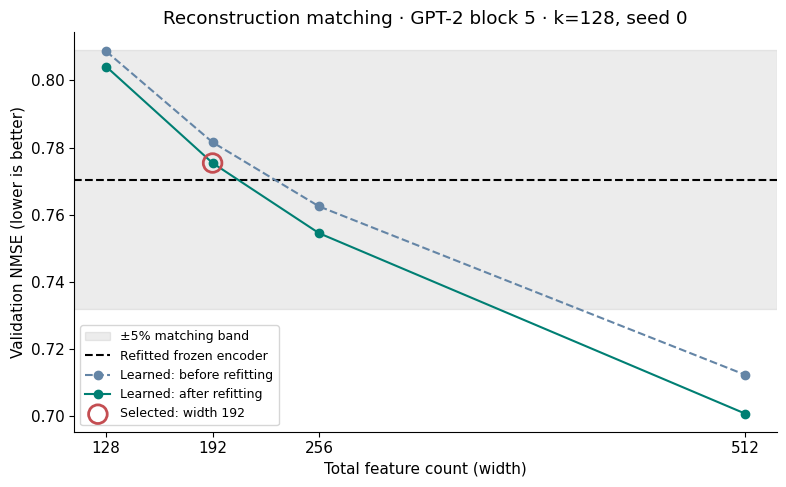

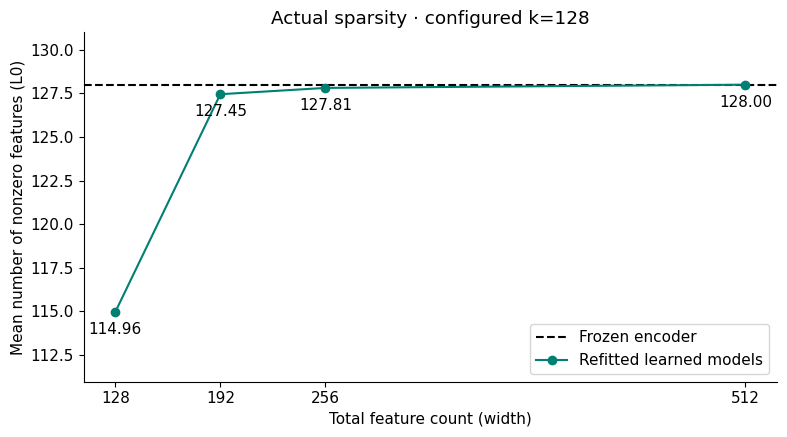

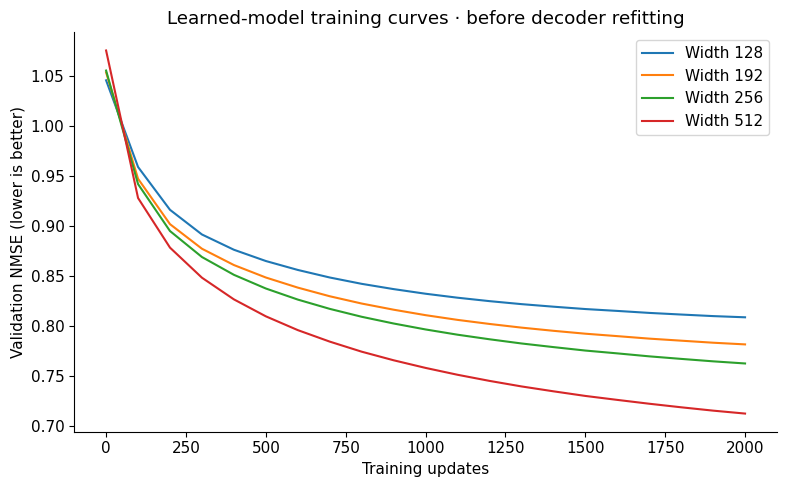

 width  nmse_before  nmse_after   l0_after  relative_nmse_gap  matched  baseline_nmse  baseline_l0
   128     0.808670    0.804124 114.957062           0.043794     True       0.770386        128.0
   192     0.781543    0.775377 127.450172           0.006479     True       0.770386        128.0
   256     0.762448    0.754463 127.811547           0.020669     True       0.770386        128.0
   512     0.712295    0.700732 127.997140           0.090413    False       0.770386        128.0

Selected reference: width 192
Figures and CSV files saved to: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/narrow_references/figures
Selection saved to: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/narrow_references/reference_selection.json


In [30]:
import json
import pandas as pd
import matplotlib.pyplot as plt

search_root = pilot_root / "narrow_references"
figures_dir = search_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

widths = [128, 192, 256, 512]
rows, history_rows = [], []

baseline_saved = torch.load(
    pilot_root / "runs/k128_seed0/frozen_encoder_ridge_refit.pt",
    map_location="cpu",
    weights_only=False,
)
baseline_nmse = baseline_saved["metrics"]["after"]["nmse"]
baseline_l0 = baseline_saved["metrics"]["after"]["l0"]
tolerance = pilot_config["relative_nmse_matching_tolerance"]

for width in widths:
    folder = search_root / f"width{width}_k128_seed0"

    trained = torch.load(
        folder / "latest.pt",
        map_location="cpu",
        weights_only=False,
    )
    refitted = torch.load(
        folder / "learned_ridge_refit.pt",
        map_location="cpu",
        weights_only=False,
    )

    assert trained["completed_steps"] == 2000
    assert trained["k"] == refitted["k"] == 128
    assert trained["seed"] == refitted["seed"] == 0

    before = refitted["metrics"]["before"]
    after = refitted["metrics"]["after"]
    gap = abs(after["nmse"] - baseline_nmse) / baseline_nmse

    rows.append({
        "width": width,
        "nmse_before": before["nmse"],
        "nmse_after": after["nmse"],
        "l0_after": after["l0"],
        "relative_nmse_gap": gap,
        "matched": gap <= tolerance,
        "baseline_nmse": baseline_nmse,
        "baseline_l0": baseline_l0,
    })

    for record in trained["history"]:
        history_rows.append({"width": width, **record})

    del trained, refitted

summary = pd.DataFrame(rows).sort_values("width")
history = pd.DataFrame(history_rows).sort_values(["width", "step"])

eligible = summary[summary["matched"]]
assert len(eligible) > 0, "No reconstruction-matched reference."
selected = eligible.loc[eligible["relative_nmse_gap"].idxmin()]
selected_width = int(selected["width"])

summary.to_csv(figures_dir / "width_search_summary.csv", index=False)
history.to_csv(figures_dir / "width_search_training_history.csv", index=False)

selection = {
    "selected_width": selected_width,
    "k": 128,
    "seed": 0,
    "training_steps": 2000,
    "rule": "Closest validation NMSE after decoder refitting, within tolerance",
    "relative_nmse_tolerance": tolerance,
    "baseline_nmse": baseline_nmse,
    "reference_nmse": float(selected["nmse_after"]),
    "relative_nmse_gap": float(selected["relative_nmse_gap"]),
    "intervention_scores_used_for_selection": False,
}
with open(search_root / "reference_selection.json", "w") as file:
    json.dump(selection, file, indent=2)

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
})

def finish_plot(fig, filename):
    fig.tight_layout()
    for extension in ["png", "pdf"]:
        fig.savefig(
            figures_dir / f"{filename}.{extension}",
            bbox_inches="tight",
        )
    plt.show()
    plt.close(fig)

# 1. Reconstruction matching
fig, ax = plt.subplots(figsize=(8, 5))

ax.axhspan(
    baseline_nmse * (1 - tolerance),
    baseline_nmse * (1 + tolerance),
    color="gray", alpha=0.15, label="±5% matching band",
)
ax.axhline(
    baseline_nmse, color="black", linestyle="--",
    label="Refitted frozen encoder",
)
ax.plot(
    summary["width"], summary["nmse_before"],
    "o--", color="#6485A6", label="Learned: before refitting",
)
ax.plot(
    summary["width"], summary["nmse_after"],
    "o-", color="#007F73", label="Learned: after refitting",
)
ax.scatter(
    [selected_width], [selected["nmse_after"]],
    s=180, facecolors="none", edgecolors="#C44E52",
    linewidths=2, zorder=5, label=f"Selected: width {selected_width}",
)
ax.set(
    xlabel="Total feature count (width)",
    ylabel="Validation NMSE (lower is better)",
    title="Reconstruction matching · GPT-2 block 5 · k=128, seed 0",
    xticks=widths,
)
ax.legend(fontsize=9)
finish_plot(fig, "01_reconstruction_matching")

# 2. Actual sparsity
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(
    baseline_l0, color="black", linestyle="--",
    label="Frozen encoder",
)
ax.plot(
    summary["width"], summary["l0_after"],
    "o-", color="#007F73", label="Refitted learned models",
)
for row in summary.itertuples():
    ax.annotate(
        f"{row.l0_after:.2f}", (row.width, row.l0_after),
        xytext=(0, -16), textcoords="offset points",
        ha="center",
    )
ax.set(
    xlabel="Total feature count (width)",
    ylabel="Mean number of nonzero features (L0)",
    title="Actual sparsity · configured k=128",
    xticks=widths,
)
ax.set_ylim(summary["l0_after"].min() - 4, 131)
ax.legend(loc="lower right")
finish_plot(fig, "02_actual_sparsity")

# 3. Training curves (before decoder refitting)
fig, ax = plt.subplots(figsize=(8, 5))
for width, group in history.groupby("width"):
    ax.plot(group["step"], group["nmse"], label=f"Width {width}")

ax.set(
    xlabel="Training updates",
    ylabel="Validation NMSE (lower is better)",
    title="Learned-model training curves · before decoder refitting",
)
ax.legend()
finish_plot(fig, "03_training_curves")

print(summary.to_string(index=False))
print(f"\nSelected reference: width {selected_width}")
print("Figures and CSV files saved to:", figures_dir)
print("Selection saved to:", search_root / "reference_selection.json")

In [31]:
import json

# Read the reference choice recorded before intervention evaluation.
with open(search_root / "reference_selection.json") as file:
    selection = json.load(file)

selected_width = selection["selected_width"]
selected_dir = search_root / f"width{selected_width}_k128_seed0"

selected_checkpoint = torch.load(
    selected_dir / "learned_ridge_refit.pt",
    map_location="cpu",
    weights_only=False,
)

selected_model = TopKTranscoder(
    d_in=pilot_config["d_in"],
    n_features=selected_width,
    d_out=pilot_config["d_out"],
    k=128,
    seed=0,
)
selected_model.load_state_dict(selected_checkpoint["state_dict"])
selected_model = selected_model.to(device).eval()
selected_model.requires_grad_(False)

panel_path = pilot_root / "validation_intervention_panel.pt"
intervention_panel = torch.load(
    panel_path, map_location="cpu", weights_only=False
)

@torch.no_grad()
def evaluate_saved_panel(model, batch_size=512):
    model.eval()

    x_base = intervention_panel["x_base"]
    x_edited = intervention_panel["x_edited"]
    true_response = intervention_panel["true_response"].cpu().double()

    assert x_base.shape == x_edited.shape
    assert len(x_base) == len(true_response)
    assert torch.isfinite(true_response).all()

    predictions = []
    for start in range(0, len(x_base), batch_size):
        base_prediction, _ = model(
            x_base[start:start + batch_size].to(device)
        )
        edited_prediction, _ = model(
            x_edited[start:start + batch_size].to(device)
        )

        predictions.append(
            (edited_prediction.double() - base_prediction.double()).cpu()
        )

    predicted_response = torch.cat(predictions)
    assert predicted_response.shape == true_response.shape
    assert torch.isfinite(predicted_response).all()

    squared_error = (
        predicted_response - true_response
    ).square().sum(dim=-1)

    response_energy = true_response.square().sum(dim=-1)
    assert response_energy.sum() > 0

    return {
        "normalized_response_error": (
            squared_error.sum() / response_energy.sum()
        ).item(),
        "squared_error_per_example": squared_error,
        "true_response_energy_per_example": response_energy,
        "predicted_response": predicted_response,
    }

comparison_results = {
    "Learned narrow": evaluate_saved_panel(selected_model),
    "Frozen encoder": evaluate_saved_panel(baseline_model),
}

learned_e = comparison_results["Learned narrow"]["normalized_response_error"]
frozen_e = comparison_results["Frozen encoder"]["normalized_response_error"]
difference = frozen_e - learned_e

torch.save(
    {
        "selection": selection,
        "panel_path": str(panel_path),
        "evaluation_split": "validation",
        "exploratory": True,
        "results": comparison_results,
        "difference_frozen_minus_learned": difference,
    },
    selected_dir / "validation_intervention_comparison.pt",
)

print(f"Selected learned width: {selected_width}")
print(f"Panel examples: {len(intervention_panel['x_base'])}")
print(f"Learned response E:       {learned_e:.6f}")
print(f"Frozen encoder response E: {frozen_e:.6f}")
print(f"D = Frozen − Learned:     {difference:+.6f}")
print("\nComparison saved.")


Selected learned width: 192
Panel examples: 240
Learned response E:       0.908641
Frozen encoder response E: 0.749518
D = Frozen − Learned:     -0.159123

Comparison saved.


In [32]:
def inspect_panel_structure(obj, prefix="panel", depth=0):
    if isinstance(obj, torch.Tensor):
        print(f"{prefix}: tensor {tuple(obj.shape)}, {obj.dtype}")
    elif isinstance(obj, dict):
        for key, value in obj.items():
            inspect_panel_structure(value, f"{prefix}.{key}", depth + 1)
    elif isinstance(obj, (list, tuple)):
        print(f"{prefix}: {type(obj).__name__}, length={len(obj)}")
        if obj:
            print(f"  First item: {str(obj[0])[:200]}")
    else:
        print(f"{prefix}: {str(obj)[:200]}")

inspect_panel_structure(intervention_panel)


panel.x_base: tensor (240, 768), torch.float32
panel.x_edited: tensor (240, 768), torch.float32
panel.true_response: tensor (240, 768), torch.float32
panel.root_rows: tensor (240,), torch.int64
panel.donor_rows: tensor (240,), torch.int64
panel.root_articles: list, length=240
  First item: validation:0
panel.donor_articles: list, length=240
  First item: validation:20
panel.alpha: 0.5
panel.seed: 4001


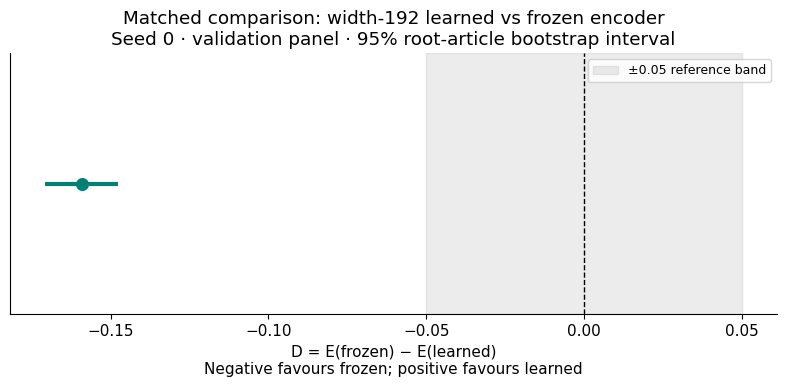

Independent resampling groups: 60 root articles
Edits per root article: 4–4
D: -0.159123
95% bootstrap interval: [-0.170822, -0.147735]
Saved to: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/narrow_references/width192_k128_seed0/analysis


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reload saved results so the analysis is reproducible.
saved_comparison = torch.load(
    selected_dir / "validation_intervention_comparison.pt",
    map_location="cpu",
    weights_only=False,
)
results = saved_comparison["results"]

learned = results["Learned narrow"]
frozen = results["Frozen encoder"]

learned_errors = learned["squared_error_per_example"].numpy()
frozen_errors = frozen["squared_error_per_example"].numpy()
energy = frozen["true_response_energy_per_example"].numpy()

np.testing.assert_allclose(
    energy,
    learned["true_response_energy_per_example"].numpy(),
)

article_ids = [str(x) for x in intervention_panel["root_articles"]]
assert len(article_ids) == len(energy)

# Sum errors and response energy within each root article.
per_example = pd.DataFrame({
    "root_article": article_ids,
    "learned_error": learned_errors,
    "frozen_error": frozen_errors,
    "response_energy": energy,
})
groups = per_example.groupby("root_article", sort=True).sum()
assert len(groups) >= 2, "Too few root articles for this bootstrap."

group_values = groups[
    ["learned_error", "frozen_error", "response_energy"]
].to_numpy()

# Paired cluster bootstrap: recompute the ratio of sums each time.
n_bootstrap = 10000
rng = np.random.default_rng(5001)
bootstrap_d = np.empty(n_bootstrap)

for b in range(n_bootstrap):
    indices = rng.integers(0, len(groups), size=len(groups))
    total = group_values[indices].sum(axis=0)
    assert total[2] > 0
    bootstrap_d[b] = (total[1] - total[0]) / total[2]

observed_d = (
    frozen_errors.sum() - learned_errors.sum()
) / energy.sum()

ci_low, ci_high = np.quantile(bootstrap_d, [0.025, 0.975])
meaningful_margin = pilot_config["meaningful_response_advantage"]

analysis_dir = selected_dir / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

summary = {
    "D_frozen_minus_learned": float(observed_d),
    "ci_95_low": float(ci_low),
    "ci_95_high": float(ci_high),
    "root_articles": len(groups),
    "panel_examples": len(energy),
    "bootstrap_replicates": n_bootstrap,
    "bootstrap_seed": 5001,
    "meaningful_advantage_margin": meaningful_margin,
    "method": "Paired root-article percentile bootstrap; fixed donors",
    "evaluation": "Exploratory validation panel, training seed 0",
}

pd.DataFrame([summary]).to_csv(
    analysis_dir / "comparison_summary.csv", index=False
)
groups.to_csv(analysis_dir / "root_article_error_totals.csv")
pd.DataFrame({"D": bootstrap_d}).to_csv(
    analysis_dir / "bootstrap_d.csv", index=False
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(
    -meaningful_margin, meaningful_margin,
    color="gray", alpha=0.15,
    label=f"±{meaningful_margin:.2f} reference band",
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.hlines(0, ci_low, ci_high, color="#007F73", linewidth=3)
ax.scatter([observed_d], [0], color="#007F73", s=70, zorder=3)
ax.set_yticks([])
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel(
    "D = E(frozen) − E(learned)\n"
    "Negative favours frozen; positive favours learned"
)
ax.set_title(
    "Matched comparison: width-192 learned vs frozen encoder\n"
    "Seed 0 · validation panel · 95% root-article bootstrap interval"
)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        analysis_dir / f"matched_intervention_difference.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print(f"Independent resampling groups: {len(groups)} root articles")
print(f"Edits per root article: "
      f"{per_example.groupby('root_article').size().min()}–"
      f"{per_example.groupby('root_article').size().max()}")
print(f"D: {observed_d:+.6f}")
print(f"95% bootstrap interval: [{ci_low:+.6f}, {ci_high:+.6f}]")
print("Saved to:", analysis_dir)

In [34]:
import copy

continuation_dir = (
    pilot_root / "continuation"
    / "k128_seed0_width192_vs_frozen_encoder"
)
continuation_dir.mkdir(parents=True, exist_ok=True)
continuation_path = continuation_dir / "latest.pt"

if continuation_path.exists():
    raise RuntimeError(
        "A continuation checkpoint already exists. "
        "Restore it instead of restarting this branch."
    )

# Original training checkpoints, before decoder refitting.
frozen_source = torch.load(
    pilot_root / "runs/k128_seed0/latest.pt",
    map_location="cpu",
    weights_only=False,
)
learned_source = torch.load(
    pilot_root / "narrow_references/width192_k128_seed0/latest.pt",
    map_location="cpu",
    weights_only=False,
)

assert frozen_source["completed_steps"] == 2000
assert learned_source["completed_steps"] == 2000
assert frozen_source["k"] == learned_source["k"] == 128
assert frozen_source["seed"] == learned_source["seed"] == 0

# Both models must resume the same batch-sampling sequence.
assert torch.equal(
    frozen_source["batch_generator_state"],
    learned_source["batch_generator_state"],
)

continuation_models = {}
continuation_optimizers = {}

for name, width, state, optimizer_state in [
    (
        "Learned narrow",
        192,
        learned_source["state_dict"],
        learned_source["optimizer"],
    ),
    (
        "Frozen encoder",
        3072,
        frozen_source["models"]["Frozen encoder"],
        frozen_source["optimizers"]["Frozen encoder"],
    ),
]:
    model = TopKTranscoder(
        d_in=768,
        n_features=width,
        d_out=768,
        k=128,
        seed=0,
    ).to(device)
    model.load_state_dict(state, strict=True)

    if name == "Frozen encoder":
        for parameter_name, parameter in model.named_parameters():
            parameter.requires_grad_(
                frozen_source["requires_grad"][name][parameter_name]
            )

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=pilot_config["learning_rate"],
    )
    optimizer.load_state_dict(optimizer_state)

    continuation_models[name] = model
    continuation_optimizers[name] = optimizer

continuation_generator = torch.Generator()
continuation_generator.set_state(
    frozen_source["batch_generator_state"]
)
continuation_completed_steps = 2000
continuation_history = []

continuation_frozen_encoder = (
    continuation_models["Frozen encoder"].W_enc.detach().clone()
)

expected_metrics = {
    "Learned narrow": max(
        learned_source["history"], key=lambda row: row["step"]
    ),
    "Frozen encoder": max(
        (
            row for row in frozen_source["history"]
            if row["variant"] == "Frozen encoder"
        ),
        key=lambda row: row["step"],
    ),
}

for name, model in continuation_models.items():
    with torch.no_grad():
        metrics = validation_metrics(model)

    expected_nmse = expected_metrics[name]["nmse"]
    assert abs(metrics["nmse"] - expected_nmse) < 1e-5, (
        f"{name}: restored NMSE differs from its training checkpoint."
    )

    continuation_history.append({
        "step": continuation_completed_steps,
        "variant": name,
        **metrics,
    })

    print(
        f"{name:15s} | Restored NMSE: {metrics['nmse']:.6f}"
        f" | L0: {metrics['l0']:.2f}"
    )

print("\nOptimizer states restored.")
print("Batch-generator states agree.")
print("Ready to continue from step 2000. No training performed.")

Learned narrow  | Restored NMSE: 0.781543 | L0: 127.45
Frozen encoder  | Restored NMSE: 0.775750 | L0: 128.00

Optimizer states restored.
Batch-generator states agree.
Ready to continue from step 2000. No training performed.


In [35]:
from tqdm.auto import tqdm

TARGET_STEP = 4000
train_cache = activation_cache["train"]

def save_continuation_checkpoint():
    payload = {
        "config": copy.deepcopy(pilot_config),
        "k": 128,
        "seed": 0,
        "widths": {
            name: model.W_enc.shape[1]
            for name, model in continuation_models.items()
        },
        "target_steps": TARGET_STEP,
        "completed_steps": continuation_completed_steps,
        "models": {
            name: {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            for name, model in continuation_models.items()
        },
        "optimizers": {
            name: optimizer.state_dict()
            for name, optimizer in continuation_optimizers.items()
        },
        "requires_grad": {
            name: {
                key: parameter.requires_grad
                for key, parameter in model.named_parameters()
            }
            for name, model in continuation_models.items()
        },
        "batch_generator_state": continuation_generator.get_state(),
        "frozen_encoder_weights": (
            continuation_frozen_encoder.detach().cpu().clone()
        ),
        "history": continuation_history,
    }

    temporary_path = continuation_dir / "latest.tmp.pt"
    torch.save(payload, temporary_path)
    temporary_path.replace(continuation_path)


assert 2000 <= continuation_completed_steps <= TARGET_STEP
assert not continuation_models["Frozen encoder"].W_enc.requires_grad

# Save the restored starting state before further training.
save_continuation_checkpoint()

for step in tqdm(
    range(continuation_completed_steps + 1, TARGET_STEP + 1)
):
    indices = torch.randint(
        len(train_cache["inputs"]),
        (pilot_config["batch_size"],),
        generator=continuation_generator,
    )
    x = train_cache["inputs"][indices].to(device)
    y = train_cache["outputs"][indices].to(device)

    for name, model in continuation_models.items():
        model.train()
        optimizer = continuation_optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        prediction, _ = model(x)
        loss = F.mse_loss(prediction, y)
        assert torch.isfinite(loss).item(), f"Nonfinite loss: {name}"

        loss.backward()
        optimizer.step()

    continuation_completed_steps = step

    if step % 100 == 0:
        assert torch.equal(
            continuation_models["Frozen encoder"].W_enc.detach(),
            continuation_frozen_encoder,
        ), "Frozen encoder weights changed."

        for name, model in continuation_models.items():
            with torch.no_grad():
                metrics = validation_metrics(model)

            continuation_history.append({
                "step": step,
                "variant": name,
                **metrics,
            })

            if step % 500 == 0:
                print(
                    f"Step {step} | {name:15s}"
                    f" | NMSE: {metrics['nmse']:.6f}"
                    f" | L0: {metrics['l0']:.2f}"
                    f" | Inactive: {metrics['inactive_fraction']:.1%}"
                )

        save_continuation_checkpoint()

print("\nTraining complete:", continuation_completed_steps)
print("Checkpoint saved:", continuation_path)
print("Frozen encoder weights unchanged.")



  0%|          | 0/2000 [00:00<?, ?it/s]

Step 2500 | Learned narrow  | NMSE: 0.774224 | L0: 127.29 | Inactive: 0.0%
Step 2500 | Frozen encoder  | NMSE: 0.772533 | L0: 128.00 | Inactive: 0.1%
Step 3000 | Learned narrow  | NMSE: 0.769284 | L0: 127.14 | Inactive: 0.0%
Step 3000 | Frozen encoder  | NMSE: 0.770966 | L0: 128.00 | Inactive: 0.0%
Step 3500 | Learned narrow  | NMSE: 0.765469 | L0: 126.99 | Inactive: 0.0%
Step 3500 | Frozen encoder  | NMSE: 0.769903 | L0: 128.00 | Inactive: 0.0%
Step 4000 | Learned narrow  | NMSE: 0.762395 | L0: 126.90 | Inactive: 0.0%
Step 4000 | Frozen encoder  | NMSE: 0.769261 | L0: 128.00 | Inactive: 0.0%

Training complete: 4000
Checkpoint saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/continuation/k128_seed0_width192_vs_frozen_encoder/latest.pt
Frozen encoder weights unchanged.


In [36]:
assert continuation_completed_steps == 4000

continuation_refitted = {}
continuation_refit_metrics = {}

for name, model in continuation_models.items():
    with torch.no_grad():
        before = validation_metrics(model)

    refitted, ridge = refit_decoder(model)

    with torch.no_grad():
        after = validation_metrics(refitted)

    continuation_refitted[name] = refitted
    continuation_refit_metrics[name] = {
        "before": before,
        "after": after,
        "ridge_absolute": ridge,
        "ridge_relative": RIDGE_RELATIVE,
    }

    # Record the actual width and training budget for this model.
    model_config = copy.deepcopy(pilot_config)
    model_config.update({
        "n_features": model.W_enc.shape[1],
        "k": model.k,
        "training_steps": continuation_completed_steps,
    })

    filename = name.lower().replace(" ", "_") + "_ridge_refit_step4000.pt"

    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu().clone()
                for key, value in refitted.state_dict().items()
            },
            "config": model_config,
            "source_variant": name,
            "source_step": continuation_completed_steps,
            "k": model.k,
            "seed": 0,
            "method": "Centered ridge regression; unpenalized output bias",
            "fit_split": "train",
            "metrics": continuation_refit_metrics[name],
        },
        continuation_dir / filename,
    )

    print(
        f"{name}\n"
        f"  NMSE: {before['nmse']:.6f} → {after['nmse']:.6f}\n"
        f"  L0:   {after['l0']:.2f}"
    )

learned_nmse = continuation_refit_metrics["Learned narrow"]["after"]["nmse"]
frozen_nmse = continuation_refit_metrics["Frozen encoder"]["after"]["nmse"]

relative_gap = abs(learned_nmse - frozen_nmse) / frozen_nmse
tolerance = pilot_config["relative_nmse_matching_tolerance"]

continuation_matching = {
    "step": continuation_completed_steps,
    "learned_width": 192,
    "frozen_width": 3072,
    "learned_nmse": learned_nmse,
    "frozen_nmse": frozen_nmse,
    "relative_nmse_gap": relative_gap,
    "tolerance": tolerance,
    "reconstruction_matched": relative_gap <= tolerance,
    "metrics": continuation_refit_metrics,
}

torch.save(
    continuation_matching,
    continuation_dir / "reconstruction_matching_step4000.pt",
)

print(f"\nRelative NMSE gap: {relative_gap:.2%}")
print(f"Within {tolerance:.0%} tolerance: {relative_gap <= tolerance}")
print("Refitted models and matching results saved.")

  0%|          | 0/127 [00:00<?, ?it/s]

Learned narrow
  NMSE: 0.762395 → 0.759588
  L0:   126.90


  0%|          | 0/127 [00:00<?, ?it/s]

Frozen encoder
  NMSE: 0.769261 → 0.767752
  L0:   128.00

Relative NMSE gap: 1.06%
Within 5% tolerance: True
Refitted models and matching results saved.


In [37]:
assert continuation_matching["reconstruction_matched"]

continuation_panel_results = {
    name: evaluate_saved_panel(model)
    for name, model in continuation_refitted.items()
}

learned_e_4000 = continuation_panel_results[
    "Learned narrow"
]["normalized_response_error"]

frozen_e_4000 = continuation_panel_results[
    "Frozen encoder"
]["normalized_response_error"]

d_4000 = frozen_e_4000 - learned_e_4000

# Load the preserved 2,000-step comparison.
previous = torch.load(
    pilot_root
    / "narrow_references/width192_k128_seed0"
    / "validation_intervention_comparison.pt",
    map_location="cpu",
    weights_only=False,
)

d_2000 = previous["difference_frozen_minus_learned"]

torch.save(
    {
        "step": 4000,
        "seed": 0,
        "k": 128,
        "panel_path": str(panel_path),
        "evaluation_split": "validation",
        "exploratory": True,
        "matching": continuation_matching,
        "results": continuation_panel_results,
        "difference_frozen_minus_learned": d_4000,
        "previous_difference_step2000": d_2000,
    },
    continuation_dir / "validation_intervention_comparison_step4000.pt",
)

print("Response error E — lower is better")
for name in ["Learned narrow", "Frozen encoder"]:
    old_e = previous["results"][name]["normalized_response_error"]
    new_e = continuation_panel_results[name]["normalized_response_error"]
    print(f"{name:15s} | Step 2000: {old_e:.6f} → Step 4000: {new_e:.6f}")

print(f"\nD at step 2000: {d_2000:+.6f}")
print(f"D at step 4000: {d_4000:+.6f}")
print(f"Change in D:    {d_4000 - d_2000:+.6f}")
print("\nComparison saved.")

Response error E — lower is better
Learned narrow  | Step 2000: 0.908641 → Step 4000: 0.868661
Frozen encoder  | Step 2000: 0.749518 → Step 4000: 0.753679

D at step 2000: -0.159123
D at step 4000: -0.114983
Change in D:    +0.044140

Comparison saved.


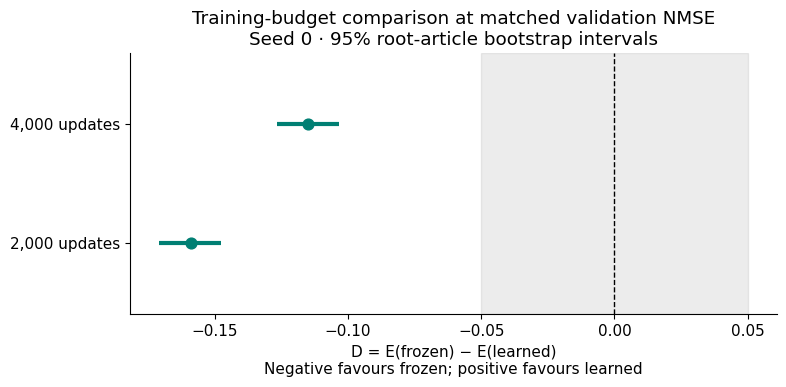

 step         D    ci_low   ci_high
 2000 -0.159123 -0.170822 -0.147735
 4000 -0.114983 -0.126822 -0.103250

Change in D: +0.044140
95% interval for change: [+0.036858, +0.051666]

Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/continuation/k128_seed0_width192_vs_frozen_encoder/analysis


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = {
    2000: (
        pilot_root / "narrow_references/width192_k128_seed0"
        / "validation_intervention_comparison.pt"
    ),
    4000: (
        continuation_dir
        / "validation_intervention_comparison_step4000.pt"
    ),
}

records = {
    step: torch.load(path, map_location="cpu", weights_only=False)
    for step, path in paths.items()
}
assert records[2000]["panel_path"] == records[4000]["panel_path"]

article_ids = [str(a) for a in intervention_panel["root_articles"]]
data = pd.DataFrame({"article": article_ids})

reference_energy = None
for step, record in records.items():
    results = record["results"]
    learned = results["Learned narrow"]
    frozen = results["Frozen encoder"]

    energy = frozen["true_response_energy_per_example"].numpy()
    np.testing.assert_allclose(
        energy, learned["true_response_energy_per_example"].numpy()
    )
    if reference_energy is None:
        reference_energy = energy
        data["energy"] = energy
    else:
        np.testing.assert_allclose(energy, reference_energy)

    data[f"error_difference_{step}"] = (
        frozen["squared_error_per_example"]
        - learned["squared_error_per_example"]
    ).numpy()

groups = data.groupby("article", sort=True).sum()
values = groups[
    ["error_difference_2000", "error_difference_4000", "energy"]
].to_numpy()

rng = np.random.default_rng(5001)
boot = np.empty((10000, 2))

for b in range(len(boot)):
    indices = rng.integers(0, len(groups), size=len(groups))
    total = values[indices].sum(axis=0)
    assert total[2] > 0
    boot[b] = total[:2] / total[2]

total = values.sum(axis=0)
observed = total[:2] / total[2]
intervals = np.quantile(boot, [0.025, 0.975], axis=0)

change = observed[1] - observed[0]
change_boot = boot[:, 1] - boot[:, 0]
change_ci = np.quantile(change_boot, [0.025, 0.975])

summary = pd.DataFrame({
    "step": [2000, 4000],
    "D": observed,
    "ci_low": intervals[0],
    "ci_high": intervals[1],
})

out_dir = continuation_dir / "analysis"
out_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(out_dir / "training_budget_comparison.csv", index=False)
pd.DataFrame([{
    "change_in_D": change,
    "ci_low": change_ci[0],
    "ci_high": change_ci[1],
    "bootstrap_seed": 5001,
    "bootstrap_replicates": len(boot),
    "root_article_groups": len(groups),
}]).to_csv(out_dir / "change_in_D.csv", index=False)

pd.DataFrame({
    "D_2000": boot[:, 0],
    "D_4000": boot[:, 1],
    "change_in_D": change_boot,
}).to_csv(out_dir / "paired_bootstrap_samples.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
margin = pilot_config["meaningful_response_advantage"]
ax.axvspan(-margin, margin, color="gray", alpha=0.15)
ax.axvline(0, color="black", linestyle="--", linewidth=1)

for i, row in summary.iterrows():
    ax.hlines(i, row["ci_low"], row["ci_high"],
              color="#007F73", linewidth=3)
    ax.scatter(row["D"], i, color="#007F73", s=60, zorder=3)

ax.set_yticks([0, 1], ["2,000 updates", "4,000 updates"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel(
    "D = E(frozen) − E(learned)\n"
    "Negative favours frozen; positive favours learned"
)
ax.set_title(
    "Training-budget comparison at matched validation NMSE\n"
    "Seed 0 · 95% root-article bootstrap intervals"
)
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        out_dir / f"training_budget_comparison.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print(summary.to_string(index=False))
print(f"\nChange in D: {change:+.6f}")
print(
    f"95% interval for change: "
    f"[{change_ci[0]:+.6f}, {change_ci[1]:+.6f}]"
)
print("\nSaved:", out_dir)

Restored step 4000; stopping at step 20000.


Training toward 8000:   0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]


STEP 8000 — AFTER REFITTING
Learned narrow  | NMSE 0.747745 | L0 126.02 | E 0.806737
Frozen encoder  | NMSE 0.765166 | L0 128.00 | E 0.750181
NMSE gap: 2.28% | Matched: True
D: -0.056556



Training toward 20000:   0%|          | 0/12000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]


STEP 20000 — AFTER REFITTING
Learned narrow  | NMSE 0.737656 | L0 125.15 | E 0.721914
Frozen encoder  | NMSE 0.761572 | L0 128.00 | E 0.749092
NMSE gap: 3.14% | Matched: True
D: +0.027177



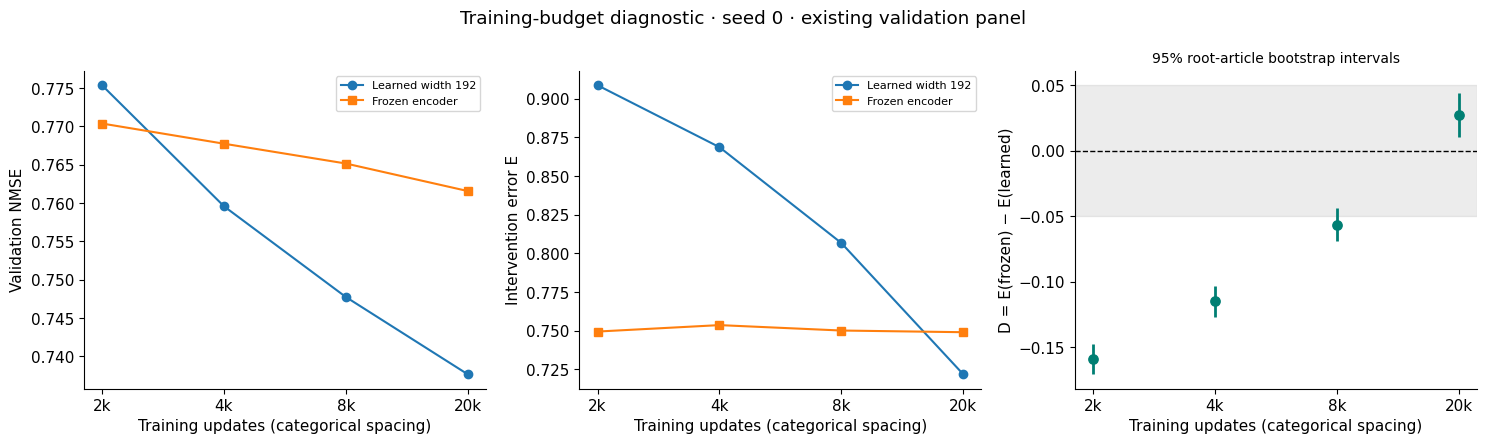


FINAL SUMMARY
 step  learned_nmse  frozen_nmse  relative_nmse_gap  matched  learned_l0  frozen_l0  learned_E  frozen_E         D    ci_low   ci_high
 2000      0.775377     0.770386           0.006479     True  127.450172      128.0   0.908641  0.749518 -0.159123 -0.170822 -0.147735
 4000      0.759588     0.767752           0.010635     True  126.901975      128.0   0.868661  0.753679 -0.114983 -0.126822 -0.103250
 8000      0.747745     0.765166           0.022768     True  126.023930      128.0   0.806737  0.750181 -0.056556 -0.069110 -0.043552
20000      0.737656     0.761572           0.031403     True  125.145239      128.0   0.721914  0.749092  0.027177  0.010158  0.043784

CHANGES BETWEEN CHECKPOINTS
 from_step  to_step  change_in_D   ci_low  ci_high
      2000     4000     0.044140 0.036858 0.051666
      4000     8000     0.058426 0.051338 0.065348
      8000    20000     0.083734 0.073951 0.093690

Finished at 20,000 updates. No further training scheduled.
Saved: /content/d

In [39]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Requires the existing TopKTranscoder, validation_metrics,
# refit_decoder, activation_cache and intervention_panel definitions.
assert torch.cuda.is_available(), "Select a GPU runtime first."
device = torch.device("cuda")
train_cache = activation_cache["train"]

MILESTONES = [8000, 20000]
TOLERANCE = pilot_config["relative_nmse_matching_tolerance"]
MARGIN = pilot_config["meaningful_response_advantage"]

branch_dir = continuation_dir / "budget_check_to20000"
branch_dir.mkdir(parents=True, exist_ok=True)
branch_latest = branch_dir / "latest.pt"

# Resume this branch if interrupted; otherwise start at step 4000.
source_path = (
    branch_latest if branch_latest.exists()
    else continuation_dir / "latest.pt"
)
source = torch.load(
    source_path, map_location="cpu", weights_only=False
)
assert source["k"] == 128 and source["seed"] == 0
assert 4000 <= source["completed_steps"] <= 20000
assert source["widths"] == {
    "Learned narrow": 192,
    "Frozen encoder": 3072,
}

budget_models = {}
budget_optimizers = {}

for name, state in source["models"].items():
    model = TopKTranscoder(
        d_in=state["W_enc"].shape[0],
        n_features=state["W_enc"].shape[1],
        d_out=state["W_dec"].shape[1],
        k=128,
        seed=0,
    ).to(device)
    model.load_state_dict(state)

    for parameter_name, parameter in model.named_parameters():
        parameter.requires_grad_(
            source["requires_grad"][name][parameter_name]
        )

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=pilot_config["learning_rate"],
    )
    optimizer.load_state_dict(source["optimizers"][name])

    budget_models[name] = model
    budget_optimizers[name] = optimizer

budget_generator = torch.Generator()
budget_generator.set_state(source["batch_generator_state"])
budget_step = source["completed_steps"]
budget_history = copy.deepcopy(source["history"])
frozen_weights = source["frozen_encoder_weights"].to(device)

assert not budget_models["Frozen encoder"].W_enc.requires_grad
assert torch.equal(
    budget_models["Frozen encoder"].W_enc.detach(), frozen_weights
)

def save_budget_checkpoint(destination):
    config = copy.deepcopy(pilot_config)
    config["training_steps"] = 20000
    config.pop("n_features", None)  # Widths differ between models.

    payload = {
        "config": config,
        "k": 128,
        "seed": 0,
        "widths": {
            name: model.W_enc.shape[1]
            for name, model in budget_models.items()
        },
        "completed_steps": budget_step,
        "target_steps": 20000,
        "models": {
            name: {
                key: tensor.detach().cpu().clone()
                for key, tensor in model.state_dict().items()
            }
            for name, model in budget_models.items()
        },
        "optimizers": {
            name: optimizer.state_dict()
            for name, optimizer in budget_optimizers.items()
        },
        "requires_grad": {
            name: {
                key: parameter.requires_grad
                for key, parameter in model.named_parameters()
            }
            for name, model in budget_models.items()
        },
        "batch_generator_state": budget_generator.get_state(),
        "frozen_encoder_weights": frozen_weights.cpu().clone(),
        "history": budget_history,
    }
    temporary = destination.with_suffix(".tmp.pt")
    torch.save(payload, temporary)
    temporary.replace(destination)

@torch.no_grad()
def budget_panel_evaluation(model):
    model.eval()
    predictions = []

    for start in range(0, len(intervention_panel["x_base"]), 512):
        base, _ = model(
            intervention_panel["x_base"][start:start + 512].to(device)
        )
        edited, _ = model(
            intervention_panel["x_edited"][start:start + 512].to(device)
        )
        predictions.append((edited.double() - base.double()).cpu())

    predicted = torch.cat(predictions)
    true = intervention_panel["true_response"].cpu().double()
    assert predicted.shape == true.shape
    assert torch.isfinite(predicted).all()

    errors = (predicted - true).square().sum(dim=-1)
    energy = true.square().sum(dim=-1)
    assert energy.sum() > 0

    return {
        "normalized_response_error": (errors.sum() / energy.sum()).item(),
        "squared_error_per_example": errors,
        "true_response_energy_per_example": energy,
        "predicted_response": predicted,
    }

def evaluate_budget_milestone(step):
    milestone_dir = branch_dir / f"step{step}"
    milestone_dir.mkdir(exist_ok=True)
    metrics, results = {}, {}

    for name, model in budget_models.items():
        with torch.no_grad():
            before = validation_metrics(model)

        refitted, ridge = refit_decoder(model)

        with torch.no_grad():
            after = validation_metrics(refitted)

        metrics[name] = {
            "before": before,
            "after": after,
            "ridge_absolute": ridge,
            "ridge_relative": RIDGE_RELATIVE,
        }
        results[name] = budget_panel_evaluation(refitted)

        torch.save(
            {
                "state_dict": {
                    key: tensor.detach().cpu().clone()
                    for key, tensor in refitted.state_dict().items()
                },
                "source_variant": name,
                "source_step": step,
                "width": model.W_enc.shape[1],
                "k": 128,
                "seed": 0,
                "fit_split": "train",
                "metrics": metrics[name],
            },
            milestone_dir / (
                name.lower().replace(" ", "_") + "_ridge_refit.pt"
            ),
        )
        del refitted

    learned_nmse = metrics["Learned narrow"]["after"]["nmse"]
    frozen_nmse = metrics["Frozen encoder"]["after"]["nmse"]
    gap = abs(learned_nmse - frozen_nmse) / frozen_nmse
    difference = (
        results["Frozen encoder"]["normalized_response_error"]
        - results["Learned narrow"]["normalized_response_error"]
    )

    record = {
        "step": step,
        "seed": 0,
        "k": 128,
        "panel_path": str(
            pilot_root / "validation_intervention_panel.pt"
        ),
        "exploratory": True,
        "evaluation_split": "validation",
        "metrics": metrics,
        "matching": {
            "relative_nmse_gap": gap,
            "tolerance": TOLERANCE,
            "reconstruction_matched": gap <= TOLERANCE,
        },
        "results": results,
        "difference_frozen_minus_learned": difference,
    }
    torch.save(record, milestone_dir / "comparison.pt")

    print(f"\nSTEP {step} — AFTER REFITTING")
    for name in results:
        print(
            f"{name:15s}"
            f" | NMSE {metrics[name]['after']['nmse']:.6f}"
            f" | L0 {metrics[name]['after']['l0']:.2f}"
            f" | E {results[name]['normalized_response_error']:.6f}"
        )
    print(f"NMSE gap: {gap:.2%} | Matched: {gap <= TOLERANCE}")
    print(f"D: {difference:+.6f}\n")


print(f"Restored step {budget_step}; stopping at step 20000.")
save_budget_checkpoint(branch_latest)

for target in MILESTONES:
    if budget_step > target:
        assert (branch_dir / f"step{target}/comparison.pt").exists()
        continue

    for step in tqdm(
        range(budget_step + 1, target + 1),
        desc=f"Training toward {target}",
    ):
        indices = torch.randint(
            len(train_cache["inputs"]),
            (pilot_config["batch_size"],),
            generator=budget_generator,
        )
        x = train_cache["inputs"][indices].to(device)
        y = train_cache["outputs"][indices].to(device)

        for name, model in budget_models.items():
            model.train()
            optimizer = budget_optimizers[name]
            optimizer.zero_grad(set_to_none=True)

            prediction, _ = model(x)
            loss = F.mse_loss(prediction, y)
            assert torch.isfinite(loss).item(), f"Nonfinite loss: {name}"
            loss.backward()
            optimizer.step()

        budget_step = step

        if step % 500 == 0:
            assert torch.equal(
                budget_models["Frozen encoder"].W_enc.detach(),
                frozen_weights,
            )
            for name, model in budget_models.items():
                with torch.no_grad():
                    measured = validation_metrics(model)
                budget_history.append({
                    "step": step, "variant": name, **measured
                })
            save_budget_checkpoint(branch_latest)

    # Save pre-refit training states; refitting uses separate copies.
    milestone_checkpoint = branch_dir / f"training_step{target}.pt"
    if not milestone_checkpoint.exists():
        save_budget_checkpoint(milestone_checkpoint)

    if not (branch_dir / f"step{target}/comparison.pt").exists():
        evaluate_budget_milestone(target)

# ---------- Joint bootstrap over all four training budgets ----------

record_paths = {
    2000: (
        pilot_root / "narrow_references/width192_k128_seed0"
        / "validation_intervention_comparison.pt"
    ),
    4000: (
        continuation_dir / "validation_intervention_comparison_step4000.pt"
    ),
    8000: branch_dir / "step8000/comparison.pt",
    20000: branch_dir / "step20000/comparison.pt",
}
records = {
    step: torch.load(path, map_location="cpu", weights_only=False)
    for step, path in record_paths.items()
}
steps = list(records)
assert len({record["panel_path"] for record in records.values()}) == 1

group_data = pd.DataFrame({
    "article": [str(a) for a in intervention_panel["root_articles"]],
})
energy_reference = None
summary_rows = []

# Read exact 2,000-step reconstruction metrics from saved files.
learned_2000 = torch.load(
    pilot_root / "narrow_references/width192_k128_seed0"
    / "learned_ridge_refit.pt",
    map_location="cpu", weights_only=False,
)
frozen_2000 = torch.load(
    pilot_root / "runs/k128_seed0/frozen_encoder_ridge_refit.pt",
    map_location="cpu", weights_only=False,
)

for step, record in records.items():
    result = record["results"]
    learned = result["Learned narrow"]
    frozen = result["Frozen encoder"]
    energy = frozen["true_response_energy_per_example"].numpy()
    np.testing.assert_allclose(
        energy, learned["true_response_energy_per_example"].numpy()
    )
    if energy_reference is None:
        energy_reference = energy
        group_data["energy"] = energy
    else:
        np.testing.assert_allclose(energy, energy_reference)

    group_data[f"difference_{step}"] = (
        frozen["squared_error_per_example"]
        - learned["squared_error_per_example"]
    ).numpy()

    if step == 2000:
        lm = learned_2000["metrics"]["after"]
        fm = frozen_2000["metrics"]["after"]
    elif step == 4000:
        lm = record["matching"]["metrics"]["Learned narrow"]["after"]
        fm = record["matching"]["metrics"]["Frozen encoder"]["after"]
    else:
        lm = record["metrics"]["Learned narrow"]["after"]
        fm = record["metrics"]["Frozen encoder"]["after"]

    gap = abs(lm["nmse"] - fm["nmse"]) / fm["nmse"]
    summary_rows.append({
        "step": step,
        "learned_nmse": lm["nmse"],
        "frozen_nmse": fm["nmse"],
        "relative_nmse_gap": gap,
        "matched": gap <= TOLERANCE,
        "learned_l0": lm["l0"],
        "frozen_l0": fm["l0"],
        "learned_E": learned["normalized_response_error"],
        "frozen_E": frozen["normalized_response_error"],
    })

groups = group_data.groupby("article", sort=True).sum()
values = groups[
    [f"difference_{step}" for step in steps] + ["energy"]
].to_numpy()

rng = np.random.default_rng(5001)
boot = np.empty((10000, len(steps)))
for b in range(len(boot)):
    indices = rng.integers(0, len(groups), size=len(groups))
    total = values[indices].sum(axis=0)
    assert total[-1] > 0
    boot[b] = total[:-1] / total[-1]

totals = values.sum(axis=0)
observed = totals[:-1] / totals[-1]
intervals = np.quantile(boot, [0.025, 0.975], axis=0)

summary = pd.DataFrame(summary_rows)
summary["D"] = observed
summary["ci_low"] = intervals[0]
summary["ci_high"] = intervals[1]

changes = []
for i in range(1, len(steps)):
    change_boot = boot[:, i] - boot[:, i - 1]
    low, high = np.quantile(change_boot, [0.025, 0.975])
    changes.append({
        "from_step": steps[i - 1],
        "to_step": steps[i],
        "change_in_D": observed[i] - observed[i - 1],
        "ci_low": low,
        "ci_high": high,
    })
changes = pd.DataFrame(changes)

analysis_dir = branch_dir / "analysis"
analysis_dir.mkdir(exist_ok=True)
summary.to_csv(analysis_dir / "budget_summary.csv", index=False)
changes.to_csv(analysis_dir / "changes_in_D.csv", index=False)
pd.DataFrame(boot, columns=steps).to_csv(
    analysis_dir / "paired_bootstrap_D.csv", index=False
)
pd.DataFrame(budget_history).to_csv(
    analysis_dir / "training_history.csv", index=False
)

# ---------- Report-ready figures ----------

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
positions = np.arange(len(steps))
labels = ["2k", "4k", "8k", "20k"]

for ax, metric, ylabel in [
    (axes[0], "nmse", "Validation NMSE"),
    (axes[1], "E", "Intervention error E"),
]:
    ax.plot(
        positions, summary[f"learned_{metric}"],
        "o-", label="Learned width 192",
    )
    ax.plot(
        positions, summary[f"frozen_{metric}"],
        "s-", label="Frozen encoder",
    )
    ax.set_xticks(positions, labels)
    ax.set_xlabel("Training updates (categorical spacing)")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

ax = axes[2]
ax.axhspan(-MARGIN, MARGIN, color="gray", alpha=0.15)
ax.axhline(0, color="black", linestyle="--", linewidth=1)

for i, row in summary.iterrows():
    color = "#007F73" if row["matched"] else "#C44E52"
    ax.vlines(i, row["ci_low"], row["ci_high"], color=color, linewidth=2)
    ax.scatter(i, row["D"], color=color, s=45)
    if not row["matched"]:
        ax.annotate(
            "Unmatched", (i, row["D"]),
            xytext=(0, 12), textcoords="offset points",
            ha="center", fontsize=8, color=color,
        )

ax.set_xticks(positions, labels)
ax.set_xlabel("Training updates (categorical spacing)")
ax.set_ylabel("D = E(frozen) − E(learned)")
ax.set_title("95% root-article bootstrap intervals", fontsize=10)

fig.suptitle(
    "Training-budget diagnostic · seed 0 · existing validation panel"
)
fig.tight_layout()
for extension in ["png", "pdf"]:
    fig.savefig(
        analysis_dir / f"budget_comparison.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print("\nFINAL SUMMARY")
print(summary.round(6).to_string(index=False))
print("\nCHANGES BETWEEN CHECKPOINTS")
print(changes.round(6).to_string(index=False))
print("\nFinished at 20,000 updates. No further training scheduled.")
print("Saved:", branch_dir)

In [40]:
import copy
import json
from tqdm.auto import tqdm

confirmation_root = pilot_root / "seed_confirmation"
confirmation_root.mkdir(parents=True, exist_ok=True)

CONFIRMATION_SEEDS = [1, 2]
CANDIDATE_WIDTHS = [128, 192, 256, 512]
INITIAL_STEPS = 2000
MATCH_TOLERANCE = pilot_config["relative_nmse_matching_tolerance"]
train_cache = activation_cache["train"]

def run_confirmation_initial(seed, width, frozen_encoder):
    variant = "Frozen encoder" if frozen_encoder else "Learned narrow"
    label = "frozen_encoder_width3072" if frozen_encoder else f"learned_width{width}"
    folder = confirmation_root / f"seed{seed}" / label
    folder.mkdir(parents=True, exist_ok=True)

    latest = folder / "latest.pt"
    refit_path_local = folder / "ridge_refit_step2000.pt"

    model = TopKTranscoder(
        d_in=pilot_config["d_in"],
        n_features=width,
        d_out=pilot_config["d_out"],
        k=128,
        seed=seed,
    ).to(device)

    if frozen_encoder:
        model.W_enc.requires_grad_(False)

    initial_encoder = model.W_enc.detach().cpu().clone()

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=pilot_config["learning_rate"],
    )
    generator = torch.Generator().manual_seed(3001)
    completed = 0
    history = []

    # Resume this run if the cell was interrupted.
    if latest.exists():
        saved = torch.load(
            latest, map_location="cpu", weights_only=False
        )
        assert saved["seed"] == seed
        assert saved["width"] == width
        assert saved["variant"] == variant
        assert saved["k"] == 128

        model.load_state_dict(saved["state_dict"])
        optimizer.load_state_dict(saved["optimizer"])
        generator.set_state(saved["batch_generator_state"])
        completed = saved["completed_steps"]
        history = saved["history"]

    assert 0 <= completed <= INITIAL_STEPS

    if frozen_encoder:
        assert torch.equal(
            model.W_enc.detach().cpu(), initial_encoder
        ), "Frozen encoder does not match its initialization."

    def save_current():
        payload = {
            "variant": variant,
            "width": width,
            "k": 128,
            "seed": seed,
            "completed_steps": completed,
            "config": {
                **copy.deepcopy(pilot_config),
                "n_features": width,
                "initial_seed": seed,
                "training_steps": INITIAL_STEPS,
            },
            "state_dict": {
                key: tensor.detach().cpu().clone()
                for key, tensor in model.state_dict().items()
            },
            "optimizer": optimizer.state_dict(),
            "batch_generator_state": generator.get_state(),
            "requires_grad": {
                key: parameter.requires_grad
                for key, parameter in model.named_parameters()
            },
            "history": history,
        }
        temporary = folder / "latest.tmp.pt"
        torch.save(payload, temporary)
        temporary.replace(latest)

    if not history:
        with torch.no_grad():
            history.append({"step": 0, **validation_metrics(model)})
        save_current()

    for step in tqdm(
        range(completed + 1, INITIAL_STEPS + 1),
        desc=f"Seed {seed} | {label}",
    ):
        indices = torch.randint(
            len(train_cache["inputs"]),
            (pilot_config["batch_size"],),
            generator=generator,
        )
        x = train_cache["inputs"][indices].to(device)
        y = train_cache["outputs"][indices].to(device)

        model.train()
        optimizer.zero_grad(set_to_none=True)
        prediction, _ = model(x)
        loss = F.mse_loss(prediction, y)
        assert torch.isfinite(loss).item()

        loss.backward()
        optimizer.step()
        completed = step

        if step % 100 == 0:
            if frozen_encoder:
                assert torch.equal(
                    model.W_enc.detach().cpu(), initial_encoder
                )
            with torch.no_grad():
                history.append({
                    "step": step,
                    **validation_metrics(model),
                })
            save_current()

    if refit_path_local.exists():
        refit_saved = torch.load(
            refit_path_local, map_location="cpu", weights_only=False
        )
        assert refit_saved["seed"] == seed
        assert refit_saved["width"] == width
        assert refit_saved["source_step"] == INITIAL_STEPS
        metrics = refit_saved["metrics"]
    else:
        with torch.no_grad():
            before = validation_metrics(model)

        refitted, ridge = refit_decoder(model)

        with torch.no_grad():
            after = validation_metrics(refitted)

        metrics = {
            "before": before,
            "after": after,
            "ridge_absolute": ridge,
            "ridge_relative": RIDGE_RELATIVE,
        }
        torch.save(
            {
                "state_dict": {
                    key: tensor.detach().cpu().clone()
                    for key, tensor in refitted.state_dict().items()
                },
                "variant": variant,
                "width": width,
                "k": 128,
                "seed": seed,
                "source_step": INITIAL_STEPS,
                "fit_split": "train",
                "metrics": metrics,
            },
            refit_path_local,
        )
        del refitted

    print(
        f"Seed {seed} | {label}"
        f" | Refitted NMSE: {metrics['after']['nmse']:.6f}"
        f" | L0: {metrics['after']['l0']:.2f}"
    )
    return {
        "variant": variant,
        "width": width,
        "nmse": metrics["after"]["nmse"],
        "l0": metrics["after"]["l0"],
        "training_checkpoint": str(latest),
        "refitted_checkpoint": str(refit_path_local),
    }


confirmation_selections = {}

for seed in CONFIRMATION_SEEDS:
    baseline = run_confirmation_initial(
        seed=seed, width=3072, frozen_encoder=True
    )
    candidates = [
        run_confirmation_initial(
            seed=seed, width=width, frozen_encoder=False
        )
        for width in CANDIDATE_WIDTHS
    ]

    for candidate in candidates:
        candidate["relative_nmse_gap"] = (
            abs(candidate["nmse"] - baseline["nmse"])
            / baseline["nmse"]
        )
        candidate["matched"] = (
            candidate["relative_nmse_gap"] <= MATCH_TOLERANCE
        )

    eligible = [c for c in candidates if c["matched"]]
    selected = (
        min(eligible, key=lambda c: c["relative_nmse_gap"])
        if eligible else None
    )

    selection = {
        "seed": seed,
        "k": 128,
        "selection_step": INITIAL_STEPS,
        "planned_evaluation_steps": [2000, 4000, 8000, 20000],
        "relative_nmse_tolerance": MATCH_TOLERANCE,
        "rule": "Closest post-refit validation NMSE within tolerance",
        "intervention_scores_used_for_selection": False,
        "baseline": baseline,
        "candidates": candidates,
        "selected": selected,
    }

    selection_path = (
        confirmation_root / f"seed{seed}" / "reference_selection.json"
    )
    if selection_path.exists():
        with open(selection_path) as file:
            existing = json.load(file)
        assert existing == selection, (
            "Selection differs from the saved decision; inspect before proceeding."
        )
    else:
        with open(selection_path, "w") as file:
            json.dump(selection, file, indent=2)

    confirmation_selections[seed] = selection

    print(f"\nSEED {seed} SELECTION")
    if selected is None:
        print("No qualifying NMSE match. Keep this as a matching failure.")
    else:
        print(
            f"Selected width: {selected['width']}\n"
            f"Learned NMSE: {selected['nmse']:.6f}\n"
            f"Frozen NMSE:  {baseline['nmse']:.6f}\n"
            f"Relative gap: {selected['relative_nmse_gap']:.2%}\n"
            f"Actual L0: learned {selected['l0']:.2f}, "
            f"frozen {baseline['l0']:.2f}"
        )

print("\nInitial seed runs and selections saved.")
print("No intervention scores evaluated in this cell.")

Seed 1 | frozen_encoder_width3072:   0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

Seed 1 | frozen_encoder_width3072 | Refitted NMSE: 0.769390 | L0: 128.00


Seed 1 | learned_width128:   0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

Seed 1 | learned_width128 | Refitted NMSE: 0.804247 | L0: 114.34


... (20 outputs left out)

Seed 2 | learned_width256 | Refitted NMSE: 0.754504 | L0: 127.82


Seed 2 | learned_width512:   0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

Seed 2 | learned_width512 | Refitted NMSE: 0.701565 | L0: 128.00

SEED 2 SELECTION
Selected width: 192
Learned NMSE: 0.775039
Frozen NMSE:  0.770338
Relative gap: 0.61%
Actual L0: learned 127.48, frozen 128.00

Initial seed runs and selections saved.
No intervention scores evaluated in this cell.


Seed 1 toward 2000: 0it [00:00, ?it/s]


Seed 1 | Step 2000 | NMSE gap 0.80% | Matched True | D -0.163160


Seed 1 toward 4000:   0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]


Seed 1 | Step 4000 | NMSE gap 0.88% | Matched True | D -0.120862


... (18 outputs left out)

Seed 2 toward 20000:   0%|          | 0/12000 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]

  0%|          | 0/127 [00:00<?, ?it/s]


Seed 2 | Step 20000 | NMSE gap 3.14% | Matched True | D +0.015911

Seed 2 finished. Stopped at 20,000 updates.


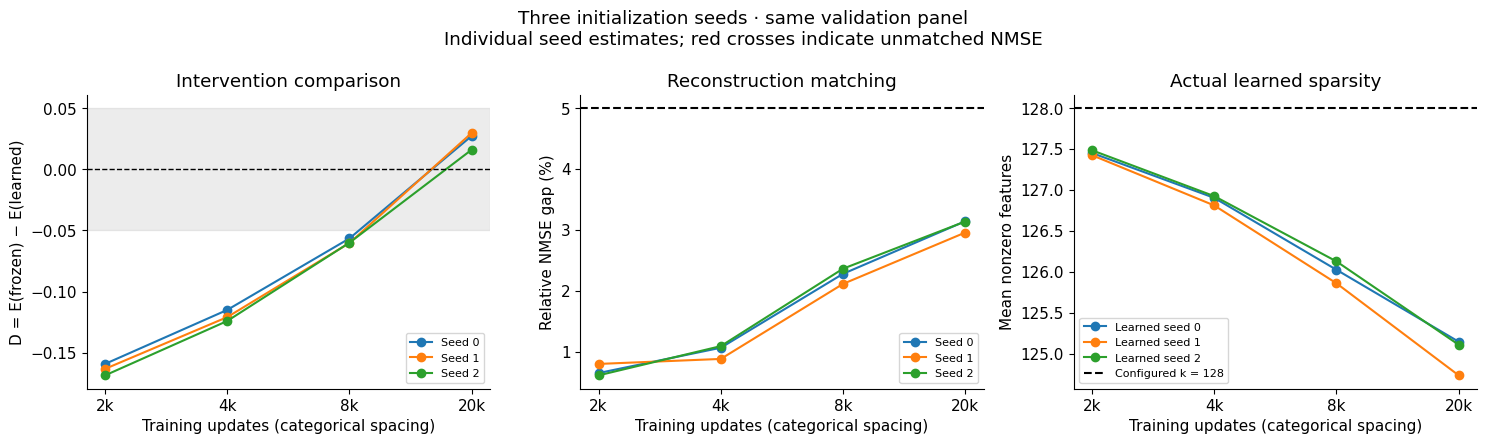


ALL SEED RESULTS
 seed  step  learned_width  learned_nmse  frozen_nmse  relative_nmse_gap  matched  learned_l0  frozen_l0  learned_E  frozen_E         D
    0  2000            192      0.775377     0.770386           0.006479     True  127.450172      128.0   0.908641  0.749518 -0.159123
    0  4000            192      0.759588     0.767752           0.010635     True  126.901975      128.0   0.868661  0.753679 -0.114983
    0  8000            192      0.747745     0.765166           0.022768     True  126.023930      128.0   0.806737  0.750181 -0.056556
    0 20000            192      0.737656     0.761572           0.031403     True  125.145239      128.0   0.721914  0.749092  0.027177
    1  2000            192      0.775528     0.769390           0.007978     True  127.422921      128.0   0.913943  0.750783 -0.163160
    1  4000            192      0.759894     0.766640           0.008800     True  126.809270      128.0   0.876629  0.755766 -0.120862
    1  8000            192    

In [41]:
import copy
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

EVALUATION_STEPS = [2000, 4000, 8000, 20000]
train_cache = activation_cache["train"]

def run_seed_schedule(seed):
    seed_dir = confirmation_root / f"seed{seed}"
    with open(seed_dir / "reference_selection.json") as file:
        selection = json.load(file)

    assert selection["selected"] is not None
    assert not selection["intervention_scores_used_for_selection"]
    width = selection["selected"]["width"]

    schedule_dir = seed_dir / "fixed_schedule"
    schedule_dir.mkdir(exist_ok=True)
    latest = schedule_dir / "latest.pt"

    # Restore either the interrupted schedule or the original 2k runs.
    resumed = (
        torch.load(latest, map_location="cpu", weights_only=False)
        if latest.exists() else None
    )

    models, optimizers = {}, {}
    generator_states = []
    histories = {}

    for name, entry in [
        ("Learned narrow", selection["selected"]),
        ("Frozen encoder", selection["baseline"]),
    ]:
        initial = torch.load(
            entry["training_checkpoint"],
            map_location="cpu",
            weights_only=False,
        )
        assert initial["completed_steps"] == 2000

        model = TopKTranscoder(
            d_in=pilot_config["d_in"],
            n_features=entry["width"],
            d_out=pilot_config["d_out"],
            k=128,
            seed=seed,
        ).to(device)

        for key, parameter in model.named_parameters():
            parameter.requires_grad_(initial["requires_grad"][key])

        model.load_state_dict(
            resumed["models"][name] if resumed
            else initial["state_dict"]
        )

        optimizer = torch.optim.Adam(
            [p for p in model.parameters() if p.requires_grad],
            lr=pilot_config["learning_rate"],
        )
        optimizer.load_state_dict(
            resumed["optimizers"][name] if resumed
            else initial["optimizer"]
        )

        models[name] = model
        optimizers[name] = optimizer
        generator_states.append(initial["batch_generator_state"])
        histories[name] = (
            resumed["histories"][name] if resumed
            else copy.deepcopy(initial["history"])
        )

        if name == "Frozen encoder":
            frozen_weights = initial["state_dict"]["W_enc"].to(device)

    assert torch.equal(generator_states[0], generator_states[1])
    assert torch.equal(
        models["Frozen encoder"].W_enc.detach(), frozen_weights
    )

    completed = resumed["completed_steps"] if resumed else 2000
    if resumed:
        assert resumed["seed"] == seed
        assert resumed["selected_width"] == width

    generator = torch.Generator()
    generator.set_state(
        resumed["batch_generator_state"] if resumed
        else generator_states[0]
    )

    def save_training(destination):
        payload = {
            "seed": seed,
            "k": 128,
            "selected_width": width,
            "completed_steps": completed,
            "selection": selection,
            "models": {
                name: {
                    key: tensor.detach().cpu().clone()
                    for key, tensor in model.state_dict().items()
                }
                for name, model in models.items()
            },
            "optimizers": {
                name: optimizer.state_dict()
                for name, optimizer in optimizers.items()
            },
            "requires_grad": {
                name: {
                    key: p.requires_grad
                    for key, p in model.named_parameters()
                }
                for name, model in models.items()
            },
            "batch_generator_state": generator.get_state(),
            "histories": histories,
        }
        temporary = destination.with_suffix(".tmp.pt")
        torch.save(payload, temporary)
        temporary.replace(destination)

    def evaluate_checkpoint(step):
        folder = schedule_dir / f"step{step}"
        folder.mkdir(exist_ok=True)
        results, metrics = {}, {}

        for name, model in models.items():
            # Reuse the already saved refit at step 2000.
            if step == 2000:
                entry = (
                    selection["selected"] if name == "Learned narrow"
                    else selection["baseline"]
                )
                saved = torch.load(
                    entry["refitted_checkpoint"],
                    map_location="cpu",
                    weights_only=False,
                )
                refitted = copy.deepcopy(model)
                refitted.load_state_dict(saved["state_dict"])
                refitted.requires_grad_(False)
                refitted.eval()
                metrics[name] = saved["metrics"]
            else:
                with torch.no_grad():
                    before = validation_metrics(model)

                refitted, ridge = refit_decoder(model)

                with torch.no_grad():
                    after = validation_metrics(refitted)

                metrics[name] = {
                    "before": before,
                    "after": after,
                    "ridge_absolute": ridge,
                    "ridge_relative": RIDGE_RELATIVE,
                }

            results[name] = budget_panel_evaluation(refitted)

            torch.save(
                {
                    "state_dict": {
                        key: tensor.detach().cpu().clone()
                        for key, tensor in refitted.state_dict().items()
                    },
                    "seed": seed,
                    "k": 128,
                    "width": model.W_enc.shape[1],
                    "source_step": step,
                    "source_variant": name,
                    "fit_split": "train",
                    "metrics": metrics[name],
                },
                folder / (
                    name.lower().replace(" ", "_") + "_ridge_refit.pt"
                ),
            )
            del refitted

        lm = metrics["Learned narrow"]["after"]
        fm = metrics["Frozen encoder"]["after"]
        gap = abs(lm["nmse"] - fm["nmse"]) / fm["nmse"]
        learned_e = results["Learned narrow"]["normalized_response_error"]
        frozen_e = results["Frozen encoder"]["normalized_response_error"]

        row = {
            "seed": seed,
            "step": step,
            "learned_width": width,
            "learned_nmse": lm["nmse"],
            "frozen_nmse": fm["nmse"],
            "relative_nmse_gap": gap,
            "matched": gap <= MATCH_TOLERANCE,
            "learned_l0": lm["l0"],
            "frozen_l0": fm["l0"],
            "learned_E": learned_e,
            "frozen_E": frozen_e,
            "D": frozen_e - learned_e,
        }
        torch.save(
            {
                "summary": row,
                "metrics": metrics,
                "results": results,
                "selection": selection,
                "panel_path": str(
                    pilot_root / "validation_intervention_panel.pt"
                ),
                "exploratory": True,
            },
            folder / "comparison.pt",
        )

        print(
            f"\nSeed {seed} | Step {step}"
            f" | NMSE gap {gap:.2%}"
            f" | Matched {row['matched']}"
            f" | D {row['D']:+.6f}"
        )

    save_training(latest)

    for target in EVALUATION_STEPS:
        result_path = schedule_dir / f"step{target}/comparison.pt"

        if completed > target:
            assert result_path.exists(), (
                f"Missing earlier evaluation: {result_path}"
            )
            continue

        for step in tqdm(
            range(completed + 1, target + 1),
            desc=f"Seed {seed} toward {target}",
        ):
            indices = torch.randint(
                len(train_cache["inputs"]),
                (pilot_config["batch_size"],),
                generator=generator,
            )
            x = train_cache["inputs"][indices].to(device)
            y = train_cache["outputs"][indices].to(device)

            for name, model in models.items():
                model.train()
                optimizer = optimizers[name]
                optimizer.zero_grad(set_to_none=True)

                prediction, _ = model(x)
                loss = F.mse_loss(prediction, y)
                assert torch.isfinite(loss).item(), name
                loss.backward()
                optimizer.step()

            completed = step

            if step % 500 == 0:
                assert torch.equal(
                    models["Frozen encoder"].W_enc.detach(),
                    frozen_weights,
                )
                for name, model in models.items():
                    with torch.no_grad():
                        measured = validation_metrics(model)
                    histories[name].append({"step": step, **measured})
                save_training(latest)

        snapshot = schedule_dir / f"training_step{target}.pt"
        if not snapshot.exists():
            save_training(snapshot)

        if not result_path.exists():
            evaluate_checkpoint(target)

    assert completed == 20000
    print(f"\nSeed {seed} finished. Stopped at 20,000 updates.")


for seed in [1, 2]:
    run_seed_schedule(seed)

# ---------- Combine seeds without pooling their uncertainty ----------

seed0_csv = (
    pilot_root
    / "continuation/k128_seed0_width192_vs_frozen_encoder"
    / "budget_check_to20000/analysis/budget_summary.csv"
)
seed0 = pd.read_csv(seed0_csv)
seed0["seed"] = 0
seed0["learned_width"] = 192

new_rows = []
for seed in [1, 2]:
    for step in EVALUATION_STEPS:
        record = torch.load(
            confirmation_root / f"seed{seed}/fixed_schedule"
            / f"step{step}/comparison.pt",
            map_location="cpu",
            weights_only=False,
        )
        new_rows.append(record["summary"])

columns = [
    "seed", "step", "learned_width",
    "learned_nmse", "frozen_nmse", "relative_nmse_gap", "matched",
    "learned_l0", "frozen_l0", "learned_E", "frozen_E", "D",
]
combined = pd.concat(
    [seed0[columns], pd.DataFrame(new_rows)[columns]],
    ignore_index=True,
).sort_values(["seed", "step"])

output_dir = confirmation_root / "combined_analysis"
output_dir.mkdir(exist_ok=True)
combined.to_csv(output_dir / "all_seed_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
positions = {step: i for i, step in enumerate(EVALUATION_STEPS)}

for seed, group in combined.groupby("seed"):
    x = [positions[step] for step in group["step"]]
    axes[0].plot(x, group["D"], "o-", label=f"Seed {seed}")
    axes[1].plot(
        x, 100 * group["relative_nmse_gap"], "o-", label=f"Seed {seed}"
    )
    axes[2].plot(
        x, group["learned_l0"], "o-", label=f"Learned seed {seed}"
    )

    unmatched = group[~group["matched"]]
    if len(unmatched):
        axes[0].scatter(
            [positions[step] for step in unmatched["step"]],
            unmatched["D"],
            marker="x", s=100, color="red", zorder=5,
        )

axes[0].axhspan(-MARGIN, MARGIN, color="gray", alpha=0.15)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_ylabel("D = E(frozen) − E(learned)")
axes[0].set_title("Intervention comparison")
axes[1].axhline(
    100 * MATCH_TOLERANCE, color="black", linestyle="--"
)
axes[1].set_ylabel("Relative NMSE gap (%)")
axes[1].set_title("Reconstruction matching")
axes[2].axhline(
    128, color="black", linestyle="--", label="Configured k = 128"
)
axes[2].set_ylabel("Mean nonzero features")
axes[2].set_title("Actual learned sparsity")

for ax in axes:
    ax.set_xticks(range(4), ["2k", "4k", "8k", "20k"])
    ax.set_xlabel("Training updates (categorical spacing)")
    ax.legend(fontsize=8)

fig.suptitle(
    "Three initialization seeds · same validation panel\n"
    "Individual seed estimates; red crosses indicate unmatched NMSE"
)
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        output_dir / f"three_seed_comparison.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print("\nALL SEED RESULTS")
print(combined.round(6).to_string(index=False))
print("\nSaved:", output_dir)

In [42]:
import json
import torch
from pathlib import Path
from transformer_lens import HookedTransformer

test_dir = pilot_root / "heldout_test"
test_dir.mkdir(parents=True, exist_ok=True)

test_protocol = {
    "model": "gpt2-small",
    "layer": 5,
    "dataset": "Salesforce/wikitext",
    "dataset_config": "wikitext-103-raw-v1",
    "split": "test",
    "n_articles_requested": 60,
    "n_windows": 256,
    "context_size": 128,
    "exclude_bos": True,
    "window_seed": 1003,
    "panel_seed": 4002,
    "roots_per_article": 4,
    "intervention": "different_article_donor_blend",
    "alpha": 0.5,
    "same_window_position_for_donor": True,
    "training_seeds": [0, 1, 2],
    "training_steps": [2000, 4000, 8000, 20000],
    "learned_width": 192,
    "frozen_encoder_width": 3072,
    "k": 128,
    "decoder_refitting": "Use saved training-data refits only",
    "relative_nmse_matching_tolerance": 0.05,
    "matching_denominator": "frozen_encoder_nmse",
    "meaningful_response_advantage": 0.05,
    "selection_on_test": False,
    "report_all_checkpoints_even_if_unmatched": True,
}

protocol_path = test_dir / "protocol.json"

if protocol_path.exists():
    with open(protocol_path) as file:
        existing_protocol = json.load(file)
    assert existing_protocol == test_protocol, (
        "A different test protocol already exists. Inspect it before proceeding."
    )
else:
    with open(protocol_path, "w") as file:
        json.dump(test_protocol, file, indent=2)

assert torch.cuda.is_available(), "Select a GPU runtime."
device = torch.device("cuda")

# Separate names prevent accidental changes to the training helpers.
test_lm = HookedTransformer.from_pretrained(
    "gpt2-small",
    device=device,
    dtype=torch.float32,
    fold_ln=False,
    center_writing_weights=False,
    center_unembed=False,
    refactor_factored_attn_matrices=False,
)
test_lm.eval()
test_lm.requires_grad_(False)
test_mlp = test_lm.blocks[5].mlp

# Verify compatibility with the existing cache.
saved_validation = activation_cache["validation"]
expected_metadata = {
    "model": "gpt2-small",
    "layer": 5,
    "context_size": 128,
    "exclude_bos": True,
    "fold_ln": False,
    "center_writing_weights": False,
    "center_unembed": False,
    "refactor_factored_attn_matrices": False,
}
for key, expected in expected_metadata.items():
    assert saved_validation["metadata"][key] == expected, key

check_generator = torch.Generator().manual_seed(6001)
check_rows = torch.randperm(
    len(saved_validation["inputs"]),
    generator=check_generator,
)[:256]

x_check = saved_validation["inputs"][check_rows].to(device)
y_check = saved_validation["outputs"][check_rows].double()

with torch.no_grad():
    replay = test_mlp(x_check.unsqueeze(1)).squeeze(1).cpu().double()

relative_replay_error = (
    torch.linalg.vector_norm(replay - y_check)
    / torch.linalg.vector_norm(y_check)
).item()

assert relative_replay_error < 1e-5, (
    f"MLP replay mismatch: {relative_replay_error:.3e}. "
    "Resolve this before extracting test activations."
)

print("Test protocol saved:", protocol_path)
print(f"MLP replay relative error: {relative_replay_error:.3e}")
print("GPT-2 restored and compatible with the existing cache.")
print("No test data loaded or model scores evaluated yet.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2-small into HookedTransformer
Test protocol saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/heldout_test/protocol.json
MLP replay relative error: 1.075e-06
GPT-2 restored and compatible with the existing cache.
No test data loaded or model scores evaluated yet.


In [43]:
import re
import hashlib
from datasets import load_dataset

def group_articles_for_test(dataset, split_name):
    title_pattern = re.compile(r"^=\s*([^=].*?)\s*=$")
    grouped = []
    current_title = None
    current_lines = []

    def save_article():
        if current_title is None:
            return

        body = "\n".join(current_lines).strip()
        if not body:
            return

        text = current_title + "\n" + body
        grouped.append({
            "article_id": f"{split_name}:{len(grouped)}",
            "title": current_title,
            "text": text,
            "text_hash": hashlib.sha256(
                text.encode("utf-8")
            ).hexdigest(),
        })

    for row in dataset:
        text = row["text"].strip()
        if not text:
            continue

        is_title = (
            bool(title_pattern.fullmatch(text))
            and not text.lstrip("= ").startswith("=")
            and text.count("=") == 2
        )

        if is_title:
            save_article()
            current_title = text
            current_lines = []
        elif current_title is not None:
            current_lines.append(text)
        else:
            raise ValueError("Text appeared before the first article title.")

    save_article()
    return grouped


# Check against complete train/validation splits, not just cached articles.
seen_hashes = set()
split_counts = {}

for split in ["train", "validation"]:
    dataset = load_dataset(
        test_protocol["dataset"],
        test_protocol["dataset_config"],
        split=split,
    )
    grouped = group_articles_for_test(dataset, split)
    split_counts[split] = len(grouped)
    seen_hashes.update(article["text_hash"] for article in grouped)
    del dataset, grouped

test_dataset = load_dataset(
    test_protocol["dataset"],
    test_protocol["dataset_config"],
    split="test",
)
test_articles = group_articles_for_test(test_dataset, "test")
del test_dataset

overlapping_articles = [
    article for article in test_articles
    if article["text_hash"] in seen_hashes
]

audit = {
    "train_article_count": split_counts["train"],
    "validation_article_count": split_counts["validation"],
    "test_article_count": len(test_articles),
    "exact_overlap_count": len(overlapping_articles),
    "overlapping_test_article_ids": [
        article["article_id"] for article in overlapping_articles
    ],
    "test_article_hashes": {
        article["article_id"]: article["text_hash"]
        for article in test_articles
    },
}

audit_path = test_dir / "article_overlap_audit.json"
if audit_path.exists():
    with open(audit_path) as file:
        assert json.load(file) == audit, (
            "Dataset audit differs from the saved version."
        )
else:
    with open(audit_path, "w") as file:
        json.dump(audit, file, indent=2)

print("Training articles:", split_counts["train"])
print("Validation articles:", split_counts["validation"])
print("Test articles:", len(test_articles))
print("Exact test overlap with train/validation:", len(overlapping_articles))

assert not overlapping_articles, (
    "Exact overlapping articles found. Resolve the overlap before sampling."
)
assert len(test_articles) >= test_protocol["n_articles_requested"]

print("\nArticle audit passed and saved.")
print("No test model scores evaluated.")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00001-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

... (4 outputs left out)

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Training articles: 29443
Validation articles: 60
Test articles: 62
Exact test overlap with train/validation: 1


AssertionError: Exact overlapping articles found. Resolve the overlap before sampling.

In [44]:
# Filter using exact text hashes, without inspecting model performance.
excluded_test_articles = [
    article for article in test_articles
    if article["text_hash"] in seen_hashes
]
eligible_test_articles = [
    article for article in test_articles
    if article["text_hash"] not in seen_hashes
]

assert len(eligible_test_articles) >= test_protocol["n_articles_requested"]
assert all(
    article["text_hash"] not in seen_hashes
    for article in eligible_test_articles
)

amendment = {
    "reason": "Exact test article overlap with train or validation",
    "rule": "Exclude every test article whose text hash occurs in either split",
    "timing": "Before test-window sampling and transcoder evaluation",
    "original_test_articles": len(test_articles),
    "eligible_test_articles": len(eligible_test_articles),
    "excluded": [
        {
            "article_id": article["article_id"],
            "title": article["title"],
            "text_hash": article["text_hash"],
        }
        for article in excluded_test_articles
    ],
    "window_seed_unchanged": test_protocol["window_seed"],
    "requested_sample_size_unchanged": test_protocol["n_articles_requested"],
}

amendment_path = test_dir / "exact_overlap_exclusion.json"
if amendment_path.exists():
    with open(amendment_path) as file:
        assert json.load(file) == amendment
else:
    with open(amendment_path, "w") as file:
        json.dump(amendment, file, indent=2)

for article in excluded_test_articles:
    print("Excluded:", article["article_id"], article["title"])

print("\nEligible test articles:", len(eligible_test_articles))
print("Requested sample:", test_protocol["n_articles_requested"])
print("Exclusion recorded. No model scores evaluated.")


Excluded: test:61 = The Hustler ( film ) =

Eligible test articles: 61
Requested sample: 60
Exclusion recorded. No model scores evaluated.


In [45]:
import random
from tqdm.auto import tqdm

test_cache_path = test_dir / "test_activation_cache.pt"

if test_cache_path.exists():
    test_cache = torch.load(
        test_cache_path, map_location="cpu", weights_only=False
    )
    assert test_cache["protocol"] == test_protocol
    print("Loaded existing test cache.")

else:
    rng = random.Random(test_protocol["window_seed"])
    tokens_per_window = test_protocol["context_size"] - 1

    selected_articles = rng.sample(
        eligible_test_articles,
        test_protocol["n_articles_requested"],
    )

    pools = []
    for article in selected_articles:
        token_ids = test_lm.tokenizer.encode(
            article["text"],
            add_special_tokens=False,
            truncation=False,
            verbose=False,
        )

        starts = list(range(
            0,
            len(token_ids) - tokens_per_window + 1,
            tokens_per_window,
        ))
        rng.shuffle(starts)

        if starts:
            pools.append({
                "article_id": article["article_id"],
                "token_ids": token_ids,
                "starts": starts,
            })

    # Same round-robin window sampling as the original notebook.
    windows, article_ids, offsets = [], [], []

    while len(windows) < test_protocol["n_windows"]:
        made_progress = False

        for pool in pools:
            if not pool["starts"]:
                continue

            start = pool["starts"].pop()
            chunk = pool["token_ids"][start:start + tokens_per_window]

            windows.append([test_lm.tokenizer.bos_token_id] + chunk)
            article_ids.append(pool["article_id"])
            offsets.append(start)
            made_progress = True

            if len(windows) == test_protocol["n_windows"]:
                break

        if not made_progress:
            raise ValueError("Selected articles contain too few full windows.")

    window_tokens = torch.tensor(windows, dtype=torch.long)
    assert window_tokens.shape == (256, 128)

    n_positions = len(windows) * tokens_per_window
    inputs = torch.empty(n_positions, 768, dtype=torch.float32)
    outputs = torch.empty_like(inputs)
    captured = {}

    def capture_test_input(module, args):
        captured["input"] = args[0].detach()

    def capture_test_output(module, args, output):
        captured["output"] = output.detach()

    input_hook = test_mlp.register_forward_pre_hook(capture_test_input)
    output_hook = test_mlp.register_forward_hook(capture_test_output)

    cursor = 0
    try:
        with torch.no_grad():
            for start in tqdm(
                range(0, len(window_tokens), 8),
                desc="Extracting test activations",
            ):
                tokens = window_tokens[start:start + 8].to(device)
                test_lm(
                    tokens,
                    return_type=None,
                    stop_at_layer=test_protocol["layer"] + 1,
                )

                x = captured["input"][:, 1:, :].reshape(-1, 768)
                y = captured["output"][:, 1:, :].reshape(-1, 768)
                count = len(x)

                inputs[cursor:cursor + count].copy_(x.cpu())
                outputs[cursor:cursor + count].copy_(y.cpu())
                cursor += count
    finally:
        input_hook.remove()
        output_hook.remove()

    assert cursor == n_positions
    assert torch.isfinite(inputs).all()
    assert torch.isfinite(outputs).all()

    test_cache = {
        "inputs": inputs,
        "outputs": outputs,
        "windows": {
            "tokens": window_tokens,
            "article_ids": article_ids,
            "article_token_offsets": torch.tensor(offsets),
            "seed": test_protocol["window_seed"],
        },
        "selected_article_ids": [
            article["article_id"] for article in selected_articles
        ],
        "article_hashes": {
            article["article_id"]: article["text_hash"]
            for article in selected_articles
        },
        "protocol": dict(test_protocol),
        "metadata": dict(activation_cache["validation"]["metadata"]),
        "overlap_exclusion_file": str(
            test_dir / "exact_overlap_exclusion.json"
        ),
    }

    temporary_path = test_dir / "test_activation_cache.tmp.pt"
    torch.save(test_cache, temporary_path)
    temporary_path.replace(test_cache_path)

# Validate article eligibility even when reloading.
eligible_ids = {a["article_id"] for a in eligible_test_articles}
cached_ids = set(test_cache["windows"]["article_ids"])
assert cached_ids <= eligible_ids
assert not (set(test_cache["article_hashes"].values()) & seen_hashes)

print("\nCached test articles:", len(cached_ids))
print("Windows:", len(test_cache["windows"]["tokens"]))
print("Input shape:", tuple(test_cache["inputs"].shape))
print("Output shape:", tuple(test_cache["outputs"].shape))
print("Saved:", test_cache_path)
print("No transcoder scores evaluated.")

Extracting test activations:   0%|          | 0/32 [00:00<?, ?it/s]


Cached test articles: 59
Windows: 256
Input shape: (32512, 768)
Output shape: (32512, 768)
Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/heldout_test/test_activation_cache.pt
No transcoder scores evaluated.


In [46]:
from collections import defaultdict
import random

test_panel_path = test_dir / "test_intervention_panel.pt"

if test_panel_path.exists():
    test_panel = torch.load(
        test_panel_path, map_location="cpu", weights_only=False
    )
    assert test_panel["protocol"] == test_protocol
    print("Loaded existing test panel.")

else:
    rng = random.Random(test_protocol["panel_seed"])
    positions_per_window = test_protocol["context_size"] - 1

    windows_by_article = defaultdict(list)
    for window_index, article_id in enumerate(
        test_cache["windows"]["article_ids"]
    ):
        windows_by_article[article_id].append(window_index)

    article_ids = sorted(windows_by_article)
    assert len(article_ids) >= 2

    root_rows, donor_rows = [], []
    root_articles, donor_articles = [], []

    for article_id in article_ids:
        other_articles = [a for a in article_ids if a != article_id]

        available_rows = [
            window_index * positions_per_window + position
            for window_index in windows_by_article[article_id]
            for position in range(positions_per_window)
        ]

        for root_row in rng.sample(
            available_rows, test_protocol["roots_per_article"]
        ):
            position = root_row % positions_per_window
            donor_article = rng.choice(other_articles)
            donor_window = rng.choice(windows_by_article[donor_article])
            donor_row = donor_window * positions_per_window + position

            root_rows.append(root_row)
            donor_rows.append(donor_row)
            root_articles.append(article_id)
            donor_articles.append(donor_article)

    x_base = test_cache["inputs"][root_rows].clone()
    x_donor = test_cache["inputs"][donor_rows].clone()
    alpha = test_protocol["alpha"]
    x_edited = (1 - alpha) * x_base + alpha * x_donor

    with torch.no_grad():
        y_base = test_mlp(
            x_base.to(device).unsqueeze(1)
        ).squeeze(1).cpu()

        y_edited = test_mlp(
            x_edited.to(device).unsqueeze(1)
        ).squeeze(1).cpu()

        # Identity control: unchanged inputs must give unchanged outputs.
        y_identity = test_mlp(
            x_base.to(device).unsqueeze(1)
        ).squeeze(1).cpu()

    torch.testing.assert_close(y_identity, y_base, rtol=0, atol=0)

    # Check that direct MLP evaluation agrees with cached outputs.
    cached_y_base = test_cache["outputs"][root_rows].double()
    replay_error = (
        torch.linalg.vector_norm(y_base.double() - cached_y_base)
        / torch.linalg.vector_norm(cached_y_base)
    ).item()
    assert replay_error < 1e-5, (
        f"Test-cache replay mismatch: {replay_error:.3e}"
    )

    test_panel = {
        "x_base": x_base,
        "x_edited": x_edited,
        "true_response": y_edited - y_base,
        "root_rows": torch.tensor(root_rows),
        "donor_rows": torch.tensor(donor_rows),
        "root_articles": root_articles,
        "donor_articles": donor_articles,
        "alpha": alpha,
        "seed": test_protocol["panel_seed"],
        "protocol": dict(test_protocol),
        "cache_replay_relative_error": replay_error,
        "identity_max_absolute_error": (
            y_identity - y_base
        ).abs().max().item(),
    }

    temporary_path = test_dir / "test_intervention_panel.tmp.pt"
    torch.save(test_panel, temporary_path)
    temporary_path.replace(test_panel_path)

assert all(
    root != donor
    for root, donor in zip(
        test_panel["root_articles"], test_panel["donor_articles"]
    )
)
assert torch.equal(
    test_panel["root_rows"] % 127,
    test_panel["donor_rows"] % 127,
)
assert torch.isfinite(test_panel["true_response"]).all()

response_energy = (
    test_panel["true_response"].double().square().sum().item()
)
assert response_energy > 0

print("\nRoot articles:", len(set(test_panel["root_articles"])))
print("Intervention examples:", len(test_panel["x_base"]))
print("Blend alpha:", test_panel["alpha"])
print(
    "Cache replay relative error:",
    f"{test_panel['cache_replay_relative_error']:.3e}",
)
print("Identity error:", test_panel["identity_max_absolute_error"])
print(f"Total true response energy: {response_energy:.6f}")
print("Saved:", test_panel_path)
print("No transcoder scores evaluated.")


Root articles: 59
Intervention examples: 236
Blend alpha: 0.5
Cache replay relative error: 1.061e-06
Identity error: 0.0
Total true response energy: 124296.235794
Saved: /content/drive/MyDrive/transcoder_pilot/gpt2_block5/heldout_test/test_intervention_panel.pt
No transcoder scores evaluated.


Test evaluation:   0%|          | 0/24 [00:00<?, ?it/s]

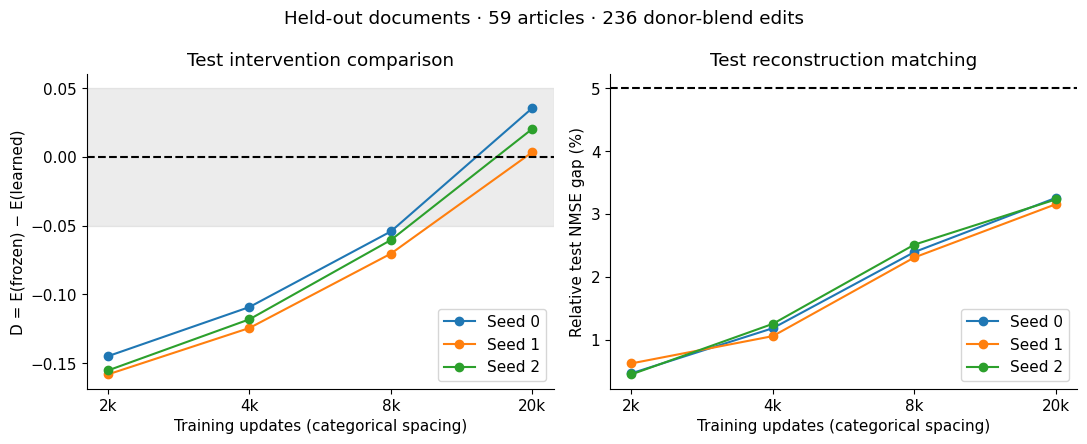


TEST RESULTS
 seed  step  learned_nmse  frozen_nmse  relative_nmse_gap  matched  learned_l0  frozen_l0  learned_E  frozen_E         D
    0  2000      0.773045     0.769444           0.004680     True  127.453187      128.0   0.896569  0.751558 -0.145011
    0  4000      0.757372     0.766455           0.011850     True  126.920952      128.0   0.863891  0.754645 -0.109246
    0  8000      0.745699     0.763993           0.023945     True  126.057579      128.0   0.805541  0.751319 -0.054223
    0 20000      0.735704     0.760465           0.032560     True  125.209553      128.0   0.714361  0.749946  0.035584
    1  2000      0.773597     0.768789           0.006254     True  127.430303      128.0   0.905885  0.747613 -0.158272
    1  4000      0.758070     0.766186           0.010593     True  126.831785      128.0   0.875744  0.751252 -0.124492
    1  8000      0.746278     0.763917           0.023090     True  125.902897      128.0   0.824371  0.753976 -0.070396
    1 20000      0

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

test_results_dir = test_dir / "model_results"
test_results_dir.mkdir(exist_ok=True)

# Locate the exact saved refitted models.
def test_model_path(seed, step, variant):
    stem = (
        "learned_narrow" if variant == "Learned narrow"
        else "frozen_encoder"
    )

    if seed in [1, 2]:
        return (
            pilot_root / f"seed_confirmation/seed{seed}/fixed_schedule"
            / f"step{step}" / f"{stem}_ridge_refit.pt"
        )

    if step == 2000:
        if variant == "Learned narrow":
            return (
                pilot_root / "narrow_references/width192_k128_seed0"
                / "learned_ridge_refit.pt"
            )
        return (
            pilot_root / "runs/k128_seed0/frozen_encoder_ridge_refit.pt"
        )

    continuation = (
        pilot_root / "continuation"
        / "k128_seed0_width192_vs_frozen_encoder"
    )
    if step == 4000:
        return continuation / f"{stem}_ridge_refit_step4000.pt"

    return (
        continuation / "budget_check_to20000"
        / f"step{step}" / f"{stem}_ridge_refit.pt"
    )


model_specs = [
    (seed, step, variant, test_model_path(seed, step, variant))
    for seed in test_protocol["training_seeds"]
    for step in test_protocol["training_steps"]
    for variant in ["Learned narrow", "Frozen encoder"]
]

# Check all paths before scoring anything.
missing = [str(path) for _, _, _, path in model_specs if not path.exists()]
assert not missing, "Missing checkpoints:\n" + "\n".join(missing)

# Same NMSE definition as validation, using the test split's own mean.
# This mean is only a metric denominator; it does not modify any model.
test_mean = test_cache["outputs"].mean(dim=0, dtype=torch.float64)
test_reference_sse = sum(
    (batch.double() - test_mean).square().sum().item()
    for batch in test_cache["outputs"].split(1024)
)
assert test_reference_sse > 0


@torch.no_grad()
def measure_test_model(model):
    model.eval()
    reconstruction_sse = 0.0
    active_count = 0
    feature_seen = torch.zeros(
        model.W_enc.shape[1], dtype=torch.bool, device=device
    )

    for start in range(0, len(test_cache["inputs"]), 512):
        x = test_cache["inputs"][start:start + 512].to(device)
        y = test_cache["outputs"][start:start + 512].to(device)

        prediction, features = model(x)
        assert torch.isfinite(prediction).all()

        reconstruction_sse += (
            prediction.double() - y.double()
        ).square().sum().item()

        active = features > 0
        active_count += active.sum().item()
        feature_seen |= active.any(dim=0)

    base_prediction, _ = model(test_panel["x_base"].to(device))
    edited_prediction, _ = model(test_panel["x_edited"].to(device))

    predicted_response = (
        edited_prediction.double() - base_prediction.double()
    ).cpu()
    true_response = test_panel["true_response"].double().cpu()

    assert torch.isfinite(predicted_response).all()
    response_errors = (
        predicted_response - true_response
    ).square().sum(dim=-1)
    response_energy = true_response.square().sum(dim=-1)

    n = len(test_cache["inputs"])
    return {
        "nmse": reconstruction_sse / test_reference_sse,
        "mse": reconstruction_sse / test_cache["outputs"].numel(),
        "l0": active_count / n,
        "inactive_fraction": (~feature_seen).float().mean().item(),
        "E": (response_errors.sum() / response_energy.sum()).item(),
        "squared_error_per_example": response_errors,
        "true_response_energy_per_example": response_energy,
        "predicted_response": predicted_response,
    }


test_measurements = {}
metric_rows = []

for seed, step, variant, path in tqdm(model_specs, desc="Test evaluation"):
    saved = torch.load(path, map_location="cpu", weights_only=False)
    assert saved["seed"] == seed
    assert saved["k"] == 128
    assert saved["source_step"] == step

    state = saved["state_dict"]
    expected_width = 192 if variant == "Learned narrow" else 3072
    assert state["W_enc"].shape == (768, expected_width)

    model = TopKTranscoder(
        d_in=768,
        n_features=expected_width,
        d_out=768,
        k=128,
        seed=seed,
    ).to(device)
    model.load_state_dict(state, strict=True)
    model.requires_grad_(False)

    metrics = measure_test_model(model)
    test_measurements[(seed, step, variant)] = metrics

    torch.save(
        {
            "seed": seed,
            "step": step,
            "variant": variant,
            "source_checkpoint": str(path),
            "protocol": dict(test_protocol),
            "panel_path": str(test_panel_path),
            "root_articles": test_panel["root_articles"],
            "donor_articles": test_panel["donor_articles"],
            "metrics": metrics,
        },
        test_results_dir
        / f"seed{seed}_step{step}_{variant.lower().replace(' ', '_')}.pt",
    )

    metric_rows.append({
        "seed": seed,
        "step": step,
        "variant": variant,
        **{
            key: metrics[key]
            for key in ["nmse", "mse", "l0", "inactive_fraction", "E"]
        },
    })
    del model, saved

comparison_rows = []
for seed in test_protocol["training_seeds"]:
    for step in test_protocol["training_steps"]:
        learned = test_measurements[(seed, step, "Learned narrow")]
        frozen = test_measurements[(seed, step, "Frozen encoder")]
        gap = abs(learned["nmse"] - frozen["nmse"]) / frozen["nmse"]

        comparison_rows.append({
            "seed": seed,
            "step": step,
            "learned_nmse": learned["nmse"],
            "frozen_nmse": frozen["nmse"],
            "relative_nmse_gap": gap,
            "matched": (
                gap <= test_protocol["relative_nmse_matching_tolerance"]
            ),
            "learned_l0": learned["l0"],
            "frozen_l0": frozen["l0"],
            "learned_E": learned["E"],
            "frozen_E": frozen["E"],
            "D": frozen["E"] - learned["E"],
        })

test_summary = pd.DataFrame(comparison_rows)
pd.DataFrame(metric_rows).to_csv(
    test_dir / "test_model_metrics.csv", index=False
)
test_summary.to_csv(test_dir / "test_comparisons.csv", index=False)

# Plot each seed separately; no pooled uncertainty implied.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
steps = test_protocol["training_steps"]
positions = {step: i for i, step in enumerate(steps)}

for seed, group in test_summary.groupby("seed"):
    x = [positions[step] for step in group["step"]]
    axes[0].plot(x, group["D"], "o-", label=f"Seed {seed}")
    axes[1].plot(
        x, 100 * group["relative_nmse_gap"], "o-", label=f"Seed {seed}"
    )
    unmatched = group[~group["matched"]]
    if len(unmatched):
        axes[0].scatter(
            [positions[step] for step in unmatched["step"]],
            unmatched["D"], marker="x", color="red", s=100, zorder=5,
        )

margin = test_protocol["meaningful_response_advantage"]
axes[0].axhspan(-margin, margin, color="gray", alpha=0.15)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("D = E(frozen) − E(learned)")
axes[0].set_title("Test intervention comparison")

axes[1].axhline(
    100 * test_protocol["relative_nmse_matching_tolerance"],
    color="black", linestyle="--",
)
axes[1].set_ylabel("Relative test NMSE gap (%)")
axes[1].set_title("Test reconstruction matching")

for ax in axes:
    ax.set_xticks(range(len(steps)), ["2k", "4k", "8k", "20k"])
    ax.set_xlabel("Training updates (categorical spacing)")
    ax.legend()

fig.suptitle("Held-out documents · 59 articles · 236 donor-blend edits")
fig.tight_layout()
for extension in ["png", "pdf"]:
    fig.savefig(
        test_dir / f"test_comparison.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print("\nTEST RESULTS")
print(test_summary.round(6).to_string(index=False))
print("\nSaved:", test_dir)
print("All checkpoints retained, including any unmatched comparisons.")

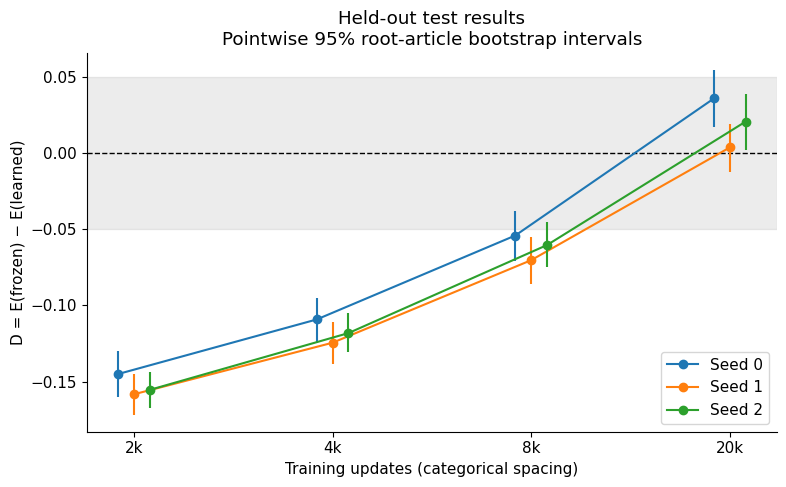


PER-SEED INTERVALS
 seed  step         D    ci_low   ci_high
    0  2000 -0.145011 -0.160307 -0.130110
    0  4000 -0.109246 -0.124409 -0.094969
    0  8000 -0.054223 -0.070649 -0.038337
    0 20000  0.035584  0.016997  0.054040
    1  2000 -0.158272 -0.171554 -0.145091
    1  4000 -0.124492 -0.138221 -0.111207
    1  8000 -0.070396 -0.086243 -0.055072
    1 20000  0.003474 -0.012277  0.019082
    2  2000 -0.155375 -0.167124 -0.143618
    2  4000 -0.118173 -0.130732 -0.105072
    2  8000 -0.060472 -0.075168 -0.045126
    2 20000  0.020441  0.001810  0.038776

MEAN OVER THREE FIXED SEEDS
 step    mean_D    ci_low   ci_high
 2000 -0.152886 -0.162952 -0.142833
 4000 -0.117304 -0.128026 -0.106610
 8000 -0.061697 -0.074131 -0.049557
20000  0.019833  0.005354  0.034115

CHANGE FROM 2K TO 20K
               comparison  change_2k_to_20k   ci_low  ci_high
                   Seed 0          0.180595 0.163523 0.197700
                   Seed 1          0.161746 0.145328 0.178119
                

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seeds = [0, 1, 2]
steps = [2000, 4000, 8000, 20000]
n_bootstrap = 10000

article_labels = np.asarray(test_panel["root_articles"])
article_ids, group_indices = np.unique(
    article_labels, return_inverse=True
)
n_groups = len(article_ids)

# Shape: article × seed × training budget.
group_differences = np.zeros((n_groups, len(seeds), len(steps)))
reference_energy = None

for si, seed in enumerate(seeds):
    for ti, step in enumerate(steps):
        loaded = {}

        for variant in ["Learned narrow", "Frozen encoder"]:
            filename = (
                f"seed{seed}_step{step}_"
                f"{variant.lower().replace(' ', '_')}.pt"
            )
            record = torch.load(
                test_results_dir / filename,
                map_location="cpu",
                weights_only=False,
            )
            assert record["root_articles"] == test_panel["root_articles"]
            assert record["donor_articles"] == test_panel["donor_articles"]
            assert record["protocol"] == test_protocol
            loaded[variant] = record["metrics"]

        learned = loaded["Learned narrow"]
        frozen = loaded["Frozen encoder"]

        energy = frozen["true_response_energy_per_example"].numpy()
        np.testing.assert_allclose(
            energy, learned["true_response_energy_per_example"].numpy()
        )
        if reference_energy is None:
            reference_energy = energy
        else:
            np.testing.assert_allclose(energy, reference_energy)

        difference = (
            frozen["squared_error_per_example"]
            - learned["squared_error_per_example"]
        ).numpy()

        group_differences[:, si, ti] = np.bincount(
            group_indices, weights=difference, minlength=n_groups
        )

group_energy = np.bincount(
    group_indices, weights=reference_energy, minlength=n_groups
)
observed = group_differences.sum(axis=0) / group_energy.sum()

rng = np.random.default_rng(5002)
bootstrap = np.empty((n_bootstrap, len(seeds), len(steps)))

for b in range(n_bootstrap):
    selected_groups = rng.integers(0, n_groups, size=n_groups)
    denominator = group_energy[selected_groups].sum()
    assert denominator > 0

    bootstrap[b] = (
        group_differences[selected_groups].sum(axis=0) / denominator
    )

intervals = np.quantile(bootstrap, [0.025, 0.975], axis=0)

rows = []
for si, seed in enumerate(seeds):
    for ti, step in enumerate(steps):
        rows.append({
            "seed": seed,
            "step": step,
            "D": observed[si, ti],
            "ci_low": intervals[0, si, ti],
            "ci_high": intervals[1, si, ti],
        })

per_seed = pd.DataFrame(rows)

# Average over the three fixed seeds, retaining shared article resamples.
mean_bootstrap = bootstrap.mean(axis=1)
mean_observed = observed.mean(axis=0)
mean_intervals = np.quantile(
    mean_bootstrap, [0.025, 0.975], axis=0
)

mean_summary = pd.DataFrame({
    "step": steps,
    "mean_D": mean_observed,
    "ci_low": mean_intervals[0],
    "ci_high": mean_intervals[1],
})

change_rows = []
for si, seed in enumerate(seeds):
    samples = bootstrap[:, si, -1] - bootstrap[:, si, 0]
    low, high = np.quantile(samples, [0.025, 0.975])
    change_rows.append({
        "comparison": f"Seed {seed}",
        "change_2k_to_20k": observed[si, -1] - observed[si, 0],
        "ci_low": low,
        "ci_high": high,
    })

mean_change = mean_bootstrap[:, -1] - mean_bootstrap[:, 0]
low, high = np.quantile(mean_change, [0.025, 0.975])
change_rows.append({
    "comparison": "Mean of three fixed seeds",
    "change_2k_to_20k": mean_observed[-1] - mean_observed[0],
    "ci_low": low,
    "ci_high": high,
})
changes = pd.DataFrame(change_rows)

analysis_dir = test_dir / "analysis"
analysis_dir.mkdir(exist_ok=True)

per_seed.to_csv(analysis_dir / "per_seed_intervals.csv", index=False)
mean_summary.to_csv(
    analysis_dir / "fixed_seed_mean_intervals.csv", index=False
)
changes.to_csv(analysis_dir / "training_budget_changes.csv", index=False)

np.savez_compressed(
    analysis_dir / "paired_article_bootstrap.npz",
    bootstrap=bootstrap,
    seeds=np.array(seeds),
    steps=np.array(steps),
    article_ids=article_ids,
    bootstrap_seed=5002,
)

fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(steps))

ax.axhspan(-0.05, 0.05, color="gray", alpha=0.15)
ax.axhline(0, color="black", linestyle="--", linewidth=1)

for si, seed in enumerate(seeds):
    x = positions + (si - 1) * 0.08
    line, = ax.plot(x, observed[si], "o-", label=f"Seed {seed}")
    ax.vlines(
        x, intervals[0, si], intervals[1, si],
        color=line.get_color(), linewidth=1.5,
    )

ax.set_xticks(positions, ["2k", "4k", "8k", "20k"])
ax.set_xlabel("Training updates (categorical spacing)")
ax.set_ylabel("D = E(frozen) − E(learned)")
ax.set_title(
    "Held-out test results\n"
    "Pointwise 95% root-article bootstrap intervals"
)
ax.legend()
fig.tight_layout()

for extension in ["png", "pdf"]:
    fig.savefig(
        analysis_dir / f"test_intervals.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

print("\nPER-SEED INTERVALS")
print(per_seed.round(6).to_string(index=False))
print("\nMEAN OVER THREE FIXED SEEDS")
print(mean_summary.round(6).to_string(index=False))
print("\nCHANGE FROM 2K TO 20K")
print(changes.round(6).to_string(index=False))
print("\nSaved:", analysis_dir)